<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/HybridQNN_QuPTTrojan_Bhowmik2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Properties Trojans (QuPT) against a quantum neural network: Bhowmik, Humble and Thapliyal (2025) step by step

This notebook re-implements, runs and checks the attack of

> Sounak Bhowmik, Travis S. Humble and Himanshu Thapliyal,
> "Quantum Properties Trojans (QuPTs) for Attacking Quantum Neural Networks",
> IEEE Computer Society Annual Symposium on VLSI (ISVLSI) 2025, DOI 10.1109/ISVLSI65124.2025.11130199,
> arXiv:2507.08202 [quant-ph], 10 July 2025.

The authors publish no code, so everything below is written from the six-page paper, with the stack it names (PennyLane).

**What the notebook does.** It builds the paper's victim, a small *fully quantum* neural network (a quanvolution filter on
4 qubits, a pooling layer, and an 8-qubit strongly-entangling variational circuit, exactly **111 trainable parameters**), and
trains it on MNIST digits 0 versus 1. It then mounts the paper's three Trojan classes on the last variational circuit during
inference and measures what they do to accuracy, precision, recall, F1 and AUC, in an ideal simulator and in a noisy one that
uses the IonQ Aria-1 depolarising rates quoted in the paper:

* **Class A**: a *noise injector*, 50 blocks of `U_i` followed by `U_i^dagger` (identity on paper, harmful only when gates are noisy).
* **Class B**: the same injector, switched on by an ancilla qubit that a malicious configuration file flips with an X gate.
* **Class C**: a *Hadamard implant* (a Hadamard on every qubit, again switched by the ancilla) that scrambles the encoded state by interference and works even on a perfect machine.

The noisy 8-qubit simulations with up to 12,800 noisy gates would take hours with a density-matrix simulator. The notebook
therefore uses an **exact** trick: the measured observable is pushed backwards through the circuit (Heisenberg picture), so
one 256 x 256 matrix replaces 200 density matrices. This engine is checked against PennyLane's `default.mixed` simulator.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, use *Runtime -> Run all*. The first cell installs
PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no IBM or IonQ account is needed.

**Runtime.** `FAST_MODE = True`: about 5 to 10 minutes on a 2-core CPU (400 training images, 8 epochs, 5-block injector).
`FAST_MODE = False`: the paper's budgets (2,000 training images, 100 epochs at learning rate 1e-4, 50-block injector), about
75 to 120 minutes; see the configuration cell.

**What you get at the end.** A table in the layout of the paper's Table II, a sweep of attack strength, confusion matrices,
drawn circuits for the victim and the three Trojans, and a per-claim verdict next to the paper's numbers.

## The paper in one page

**Problem.** Quantum neural networks (QNNs) are starting to be used for detection and classification, but little is known about
their security. The paper asks whether a *circuit-level Trojan* that exploits genuinely quantum properties (unitarity,
superposition, interference) can wreck a QNN without touching its training data.

**Threat model.** The victim downloads a QNN circuit from a domain expert and trains it on private data. The compiler and the cloud
provider are trusted, but the attacker can alter the hardware **configuration file** that the compiler downloads before each
compilation and so insert an extra instruction (an X gate on an ancilla) that triggers a Trojan already present in the circuit.
The attacker needs neither the training data nor access after training, and the Trojan survives retraining.

**Victim QNN (Fig. 6, Table I).** Quantum convolution (PQC kernel on 4 qubits, after Henderson et al. quanvolution) ->
quantum pooling (parametrised controlled-RZ gates, then the first qubit is measured in Z) -> variational circuit (VQC) on
8 qubits built from strongly-entangling layers; the Z expectation of the first qubit is the logit. PennyLane, 111 parameters,
Adam, learning rate 1e-4, step scheduler (step 10, gamma 0.75), binary cross-entropy, batch 64, 100 epochs, 1024 shots.

**Data.** MNIST digits 0 and 1: 2,000 training images and 200 further images for validation/test.

**Trojans (Section IV).**
* *Class A*: 50 repetitions of `U_i^dagger U_i`, each `U_i` of depth 3 = Hadamards, then a ring of CNOT, Ising XX, YY, ZZ and SWAP gates with block-specific angles.
* *Class B*: the same, controlled by an ancilla that is |0> in benign operation; a "Trojan shield" (two cross-connected CNOTs between the ancilla and a data qubit) keeps the compiler from deleting the idle ancilla.
* *Class C*: Hadamard on every qubit (controlled by the ancilla) applied to the encoded state: interference, `H^n|psi>`.

**Environments.** Ideal (`default.qubit`) and noisy (IonQ Aria-1 depolarising channels, `r1q = 5e-4`, `r2q = 13.3e-3`).

**Claims (Table II and Section VI).** All numbers are on the 200-image test set (100 zeros, 100 ones; "positive" = digit 1).

| Environment | Attack | Acc (%) | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|---|
| Ideal | none | 70.00 | 1.00 | 0.40 | 0.5651 | 0.9244 |
| Ideal | A, B | 70.00 | 1.00 | 0.40 | 0.5651 | 0.9244 |
| Ideal | C | 50.00 | 0.00 | 0.00 | 0.00 | 0.3808 |
| IonQ Aria-1 | none | 65.00 | 1.00 | 0.30 | 0.4615 | 0.9198 |
| IonQ Aria-1 | A, B | 57.00 | 1.00 | 0.14 | 0.2456 | 0.8998 |
| IonQ Aria-1 | C | 50.00 | 0.00 | 0.00 | 0.00 | 0.3856 |

The abstract's headline: "the most impactful QuPT caused a deterioration of 23% accuracy" (relative drop 65 -> 50 under IonQ noise).
Table II's accuracy and recall pair also fixes the confusion matrices: 70 % with recall 0.40 means 40 of 100 ones found and all
100 zeros correct. The benign model is therefore strongly biased towards class 0 (the paper says so itself).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane | PennyLane 0.45.1 (`default.qubit` for training); a NumPy Heisenberg engine for the noisy runs, validated against `default.mixed` |
| Data | MNIST 0/1, 2,000 train, 200 more | MNIST 0/1 from the original `mnist.npz`: 2,000 train, 200 validation (monitoring only), 200 test (100 + 100, inferred from Table II) |
| Image size | not stated | `# CHOICE:` centre crop 24 x 24, 3 x 3 block mean -> **8 x 8**, pixels in [0, 1] |
| Quanvolution kernel | 4 qubits, PQC | `# CHOICE:` 2 x 2 patch, stride 2 -> 16 patches; `RY(pi * pixel)` encoding; 1 `StronglyEntanglingLayers` layer (12 parameters) |
| Pooling | controlled-RZ gates, measure first qubit in Z | 3 CRZ (control qubit i+1, target i; 3 parameters), then `<Z_0>`. Parameters: 12 + 3 + VQC = 111 |
| Variational circuit | strongly entangling, 8 qubits, 111 parameters in total | `# CHOICE:` 4 `StronglyEntanglingLayers` layers x 8 qubits x 3 = 96 parameters, which gives exactly 111 in total |
| Feeding 16 conv. outputs into 8 qubits | not stated | `# CHOICE:` `RY(pi/2 (f+1))` from outputs 0-7, then `RZ(pi/2 (f+1))` from outputs 8-15 |
| Logit and loss | Z expectation of qubit 0, BCE | `# CHOICE:` `P(class 1) = (1 - <Z_0>)/2`, BCE on that probability |
| Initial weights | not stated | `# CHOICE:` uniform on [0, 2 pi] (PennyLane `TorchLayer` default) |
| Optimiser | Adam, lr 1e-4, StepLR(10, 0.75), batch 64, 100 epochs | same in the full run. FAST_MODE: lr 1e-2, 8 epochs, 400 images |
| Shots | 1024 (default) | exact expectation for training; 1024-shot sampling of `<Z_0>` for every reported test metric |
| Ideal noise-free device | `default.qubit` | same circuits, exact |
| Noisy device | IonQ Aria-1 cloud simulator, depolarising `r1q = 5e-4`, `r2q = 13.3e-3` | `# CHOICE:` local depolarising channel after every gate: with probability r the qubit(s) are replaced by the maximally mixed state; SWAP, Ising and controlled gates count as **one** 2-qubit gate each (IonQ compiles to its native gates); encoding gates are noise-free |
| Where the noise acts | whole QNN | convolution, pooling, VQC **and** the Trojan all run noisy |
| Class A block `U_i` | Hadamard, then ring of CNOT, Ising XX, YY, ZZ, SWAP; depth 3; 50 blocks; angles per block | `# CHOICE:` ring over the 8 data qubits (`q -> q+1 mod 8`), one angle each for XX, YY, ZZ per block drawn uniformly in [0, 2 pi]; the block is followed by its exact inverse (50 x 256 = 12,800 gates) |
| Trojan position | "mounted on the last VQC" | `# CHOICE:` immediately after the encoding gates, before the trainable layers |
| Class B | injector controlled by an ancilla | circuit with a 9th qubit drawn and checked noise-free; in the **noisy** runs class B is simulated as class A (the paper reports one row "A, B" because the effect is the same) |
| Trojan shield | two cross-connected CNOTs | `# CHOICE:` `CNOT(ancilla -> q7)` then `CNOT(q7 -> ancilla)` after the VQC; qubit 7 is not measured, so the output is unchanged (asserted) |
| Class C | H on every qubit, controlled by the ancilla | 8 controlled Hadamards, trigger = X on the ancilla |
| Metrics | accuracy, precision, recall, F1, AUC; "Impact (%)" | same; impact = (benign - attacked) / benign x 100 |
| Seeds / repeats | one run, no seed | seed 42 for the main victim plus extra victims with other seeds (mean +- std over victims) |
| Classical baseline | none | RandomForest and SVC(rbf) on the 16 quanvolution features and on the 64 pixels |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, scikit-learn, matplotlib.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo in about 5-10 minutes. False: the paper's budgets (about 75-120 minutes on a 2-core CPU).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # not used: no real hardware is needed, everything is simulated locally
DATA_DIR  = "data"          # where mnist.npz is cached
MNIST_NPZ_PATH = ""         # optional: path of an uploaded mnist.npz (skips the download)

# --- sizes (paper: 2000 training images, 200 further images) ---
N_TEST = 200                # 100 zeros + 100 ones (Table II implies a balanced 200-image test set)
if FAST_MODE:
    N_TRAIN, N_VAL = 400, 100
else:
    N_TRAIN, N_VAL = 2000, 200

# --- training (paper Table I) ---
BATCH, STEP_SIZE, GAMMA = 64, 10, 0.75      # Adam, StepLR(step 10, gamma 0.75)
PAPER_LR, PAPER_EPOCHS = 1e-4, 100
if FAST_MODE:
    # victims: (name, seed, learning rate, epochs). CHOICE: a larger learning rate so that 8 epochs are enough for a demo.
    VICTIMS = [("victim-1", SEED, 1e-2, 8), ("victim-2", SEED + 1, 1e-2, 8)]
else:
    # the first victim follows Table I literally; two further, better-trained victims show how robust the findings are
    VICTIMS = [("paper-config", SEED, PAPER_LR, PAPER_EPOCHS), ("lr1e-2-a", SEED + 1, 1e-2, 12), ("lr1e-2-b", SEED + 2, 1e-2, 12)]

# --- noise and attack (paper Table I and Section IV) ---
SHOTS = 1024
R1Q, R2Q = 5e-4, 13.3e-3                    # IonQ Aria-1 depolarising rates quoted in the paper
INJ_DEPTH = 3                               # depth of every U_i
INJ_REPS = 5 if FAST_MODE else 50           # number of U_i^dagger U_i blocks (paper: 50)
SWEEP_REPS = [0, 1, 2, 3, 5] if FAST_MODE else [0, 1, 2, 5, 10, 20, 35, 50]
INJ_SEED = SEED + 7                         # CHOICE: seed of the random angles phi_i, omega_i, theta_i
print("FAST_MODE =", FAST_MODE, "| N_TRAIN/N_VAL/N_TEST =", N_TRAIN, N_VAL, N_TEST, "| victims:", VICTIMS, "| injector blocks:", INJ_REPS)

FAST_MODE = False | N_TRAIN/N_VAL/N_TEST = 2000 200 200 | victims: [('paper-config', 42, 0.0001, 100), ('lr1e-2-a', 43, 0.01, 12), ('lr1e-2-b', 44, 0.01, 12)] | injector blocks: 50


In [3]:
import os, io, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

import pennylane as qml
from pennylane import numpy as pnp

np.random.seed(SEED)                         # PennyLane's own random draws (weight initialisation) use numpy's global generator
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The data: MNIST digits 0 and 1

MNIST (LeCun et al.) holds 70,000 28 x 28 grey-scale images of handwritten digits, 60,000 for training and 10,000 for testing.
The paper uses only the digits 0 and 1 and a "small subset" of 2,000 training images plus 200 further images, because simulating
a quantum convolution is expensive. We do the same.

The file is downloaded once (the original `mnist.npz` that Keras uses, then OpenML as a fallback) and cached in `DATA_DIR`.
Sampling is **class balanced** (half zeros, half ones) with `numpy.random.default_rng(SEED)`; the training, validation and test
images come from disjoint indices (training and validation from MNIST's training part, test from MNIST's test part). Nothing is
fitted here, so there is nothing to leak: the only "preprocessing" is a fixed down-sampling to 8 x 8 (section 2).
Label **1 = digit "1" (positive class)**, label 0 = digit "0".

In [4]:
def load_mnist():
    """Return x_train (60000,28,28) uint8, y_train, x_test (10000,28,28), y_test."""
    path = MNIST_NPZ_PATH or os.path.join(DATA_DIR, "mnist.npz")
    def valid(p):                                                           # a truncated or corrupt cache is rejected
        try: return np.load(p)["x_train"].shape == (60000, 28, 28)
        except Exception: return False
    if not (os.path.exists(path) and valid(path)):
        try:
            import requests
            url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
            for attempt in range(5):                                      # the download is retried; a truncated file is rejected
                try:
                    r = requests.get(url, timeout=300); r.raise_for_status()
                    if len(r.content) == 11490434: break
                except requests.RequestException: pass
                time.sleep(2)
            else:
                raise RuntimeError("download incomplete")
            with open(path, "wb") as fh: fh.write(r.content)
            print("downloaded", url)
        except Exception as e:                    # fallback: OpenML (first 60000 rows = MNIST training part)
            print("direct download failed (%s); trying OpenML" % type(e).__name__)
            from sklearn.datasets import fetch_openml
            X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
            X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(np.uint8)
            np.savez(path, x_train=X[:60000], y_train=y[:60000], x_test=X[60000:], y_test=y[60000:])
    d = np.load(path)
    return d["x_train"], d["y_train"], d["x_test"], d["y_test"]

x_tr_all, y_tr_all, x_te_all, y_te_all = load_mnist()
print("MNIST: train", x_tr_all.shape, "test", x_te_all.shape, "| pixel dtype", x_tr_all.dtype, "range", x_tr_all.min(), x_tr_all.max())

def balanced_indices(y, per_class, r, exclude=()):
    out = []
    for digit in (0, 1):
        pool = np.setdiff1d(np.flatnonzero(y == digit), np.asarray(exclude, dtype=int))
        out.append(r.choice(pool, per_class, replace=False))
    return r.permutation(np.concatenate(out))

tr_idx = balanced_indices(y_tr_all, N_TRAIN // 2, rng)
va_idx = balanced_indices(y_tr_all, N_VAL // 2, rng, exclude=tr_idx)
te_idx = balanced_indices(y_te_all, N_TEST // 2, rng)
assert len(set(tr_idx) & set(va_idx)) == 0
x_train, y_train = x_tr_all[tr_idx], y_tr_all[tr_idx].astype(int)
x_val,   y_val   = x_tr_all[va_idx], y_tr_all[va_idx].astype(int)
x_test,  y_test  = x_te_all[te_idx], y_te_all[te_idx].astype(int)
for name, y in (("train", y_train), ("validation", y_val), ("test", y_test)):
    print(f"{name:10s}: {len(y):5d} images | zeros {int((y == 0).sum())}, ones {int((y == 1).sum())}")

MNIST: train (60000, 28, 28) test (10000, 28, 28) | pixel dtype uint8 range 0 255
train     :  2000 images | zeros 1000, ones 1000
validation:   200 images | zeros 100, ones 100
test      :   200 images | zeros 100, ones 100


## Dataset Exploration and Visualisation

Everything in this section is computed from the real MNIST images that the experiment uses. First the shape, the feature names
(the 784 pixels `p0 ... p783`, row by row), the original label values and class counts; then the real class distribution, a gallery
of real images, and 2-D scatter plots of real observations coloured by their ground-truth digit:
the raw PCA coordinates (PCA fitted on the training split), and the same coordinates of the 8 x 8 down-sampled image scaled
to the angle range [0, pi] that the quantum circuit uses (min-max fitted on the training split, test points clipped).

original MNIST: x_train (60000, 28, 28) -> flattened feature matrix (60000, 784)
feature names : p0 ... p783 (pixel intensities 0-255, row-major 28 x 28); first five: ['p0', 'p1', 'p2', 'p3', 'p4']
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (digits 0-9)


,0,1,2,3,4,5,6,7,8,9
MNIST train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
MNIST test,980,1135,1032,1010,982,892,958,1028,974,1009



subset used here (only digits 0 and 1; label 1 = digit '1' = positive class):
                   train  validation  test
digit 0 (label 0)   1000         100   100
digit 1 (label 1)   1000         100   100


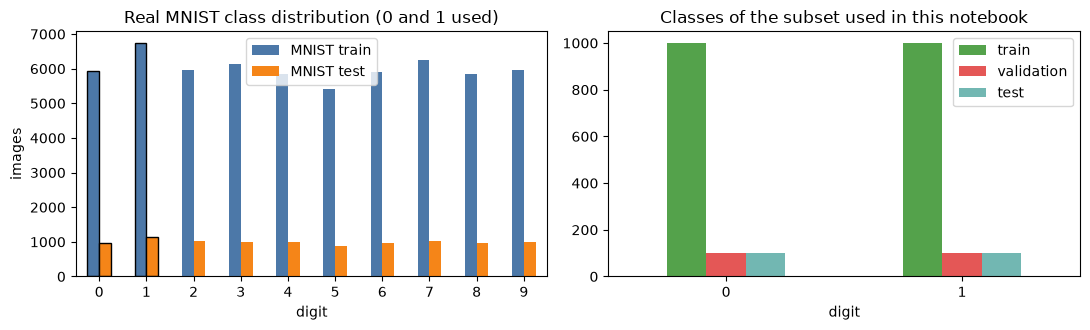

In [5]:
### 1. Shape, features, labels, class counts
print("original MNIST: x_train", x_tr_all.shape, "-> flattened feature matrix", (x_tr_all.shape[0], 784))
print("feature names : p0 ... p783 (pixel intensities 0-255, row-major 28 x 28); first five:", [f"p{i}" for i in range(5)])
print("original label values:", sorted(np.unique(y_tr_all).tolist()), "(digits 0-9)")
cnt_all = pd.DataFrame({"MNIST train": pd.Series(y_tr_all).value_counts().sort_index(),
                        "MNIST test": pd.Series(y_te_all).value_counts().sort_index()})
display(cnt_all.T)
print("\nsubset used here (only digits 0 and 1; label 1 = digit '1' = positive class):")
print(pd.DataFrame({"train": np.bincount(y_train, minlength=2), "validation": np.bincount(y_val, minlength=2),
                    "test": np.bincount(y_test, minlength=2)}, index=["digit 0 (label 0)", "digit 1 (label 1)"]))

### 2. Real class distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cnt_all.plot.bar(ax=ax[0], color=["#4C78A8", "#F58518"], rot=0); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
ax[0].set_title("Real MNIST class distribution (0 and 1 used)")
for k in (0, 1): ax[0].patches[k].set_edgecolor("k"); ax[0].patches[10 + k].set_edgecolor("k")
sub = pd.DataFrame({"train": np.bincount(y_train), "validation": np.bincount(y_val), "test": np.bincount(y_test)}, index=["0", "1"])
sub.plot.bar(ax=ax[1], rot=0, color=["#54A24B", "#E45756", "#72B7B2"]); ax[1].set_title("Classes of the subset used in this notebook"); ax[1].set_xlabel("digit")
plt.tight_layout(); plt.show()

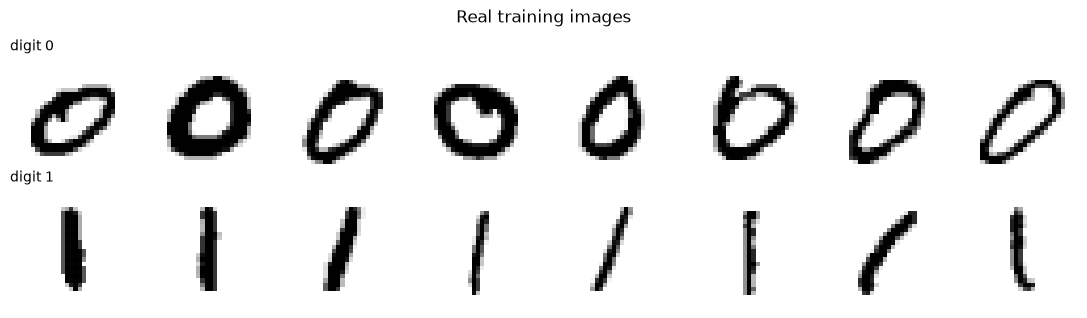

In [6]:
### 3. Gallery of real images (first 8 per class from the training subset)
fig, axs = plt.subplots(2, 8, figsize=(11, 3.2))
for r_, digit in enumerate((0, 1)):
    ids = np.flatnonzero(y_train == digit)[:8]
    for c_, i in enumerate(ids):
        axs[r_, c_].imshow(x_train[i], cmap="gray_r"); axs[r_, c_].axis("off")
    axs[r_, 0].set_title(f"digit {digit}", loc="left", fontsize=10)
plt.suptitle("Real training images"); plt.tight_layout(); plt.show()

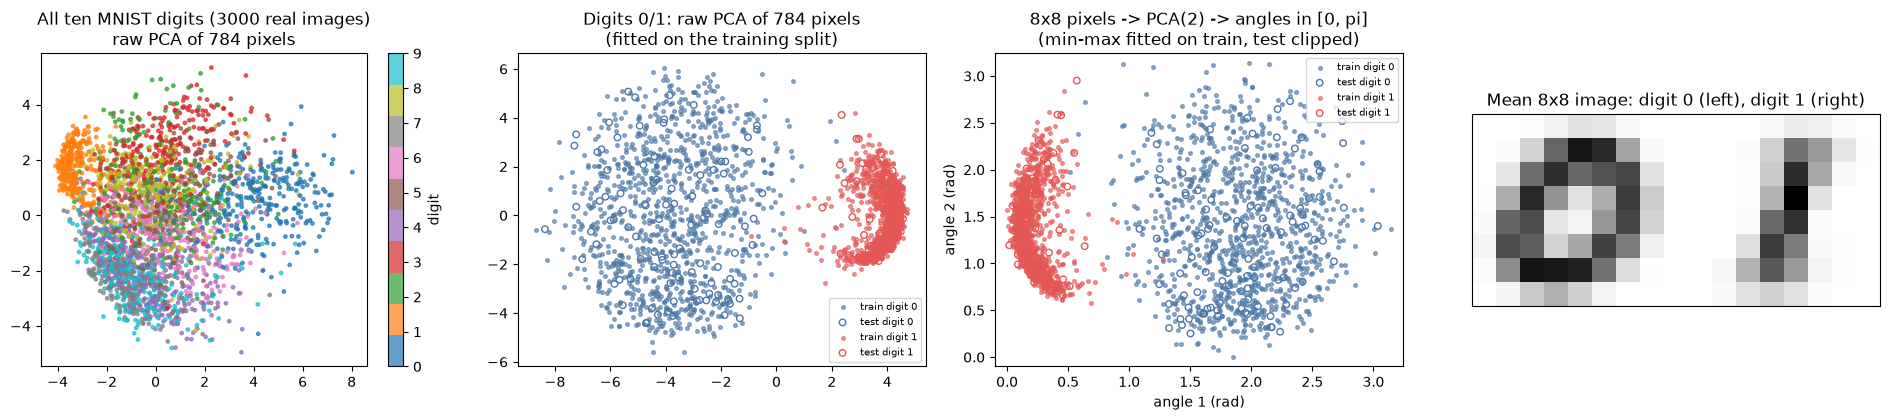

the two digits are almost linearly separable in pixel space, so the classification itself is easy;
the paper's 70 % benign accuracy comes from an under-trained, biased circuit, not from a hard task.


In [7]:
### 4. Real observations in 2-D: raw PCA, then the same coordinates scaled to [0, pi]
def to_8x8(x):
    """CHOICE: centre crop 24 x 24 and 3 x 3 block mean -> 8 x 8 image in [0, 1] (fixed transform, nothing is fitted)."""
    x = np.asarray(x, dtype=np.float64) / 255.0
    x = x[:, 2:26, 2:26]
    return x.reshape(-1, 8, 3, 8, 3).mean(axis=(2, 4))

img_train, img_val, img_test = to_8x8(x_train), to_8x8(x_val), to_8x8(x_test)

# (a) all ten digits in the 784-pixel space (context: where 0 and 1 sit among all digits), PCA fitted on a training sample
ctx_idx = np.random.default_rng(SEED).choice(len(x_tr_all), 3000, replace=False)
pca_ctx = PCA(n_components=2, random_state=SEED).fit(x_tr_all[ctx_idx].reshape(3000, -1) / 255.0)
zc = pca_ctx.transform(x_tr_all[ctx_idx].reshape(3000, -1) / 255.0)

# (b) the subset: PCA of the 784 raw pixels fitted on the training split
pca_raw = PCA(n_components=2, random_state=SEED).fit(x_train.reshape(len(x_train), -1) / 255.0)
z_tr, z_te = (pca_raw.transform(a.reshape(len(a), -1) / 255.0) for a in (x_train, x_test))

# (c) the 64 down-sampled pixels -> PCA(2) fitted on train -> MinMax [0, pi] fitted on train, test clipped
pca_64 = PCA(n_components=2, random_state=SEED).fit(img_train.reshape(len(img_train), -1))
mm = MinMaxScaler((0, np.pi)).fit(pca_64.transform(img_train.reshape(len(img_train), -1)))
a_tr = mm.transform(pca_64.transform(img_train.reshape(len(img_train), -1)))
a_te = np.clip(mm.transform(pca_64.transform(img_test.reshape(len(img_test), -1))), 0, np.pi)

cols = {0: "#4C78A8", 1: "#E45756"}
fig, axs = plt.subplots(1, 4, figsize=(19, 4.3))
sc = axs[0].scatter(zc[:, 0], zc[:, 1], c=y_tr_all[ctx_idx], cmap="tab10", s=6, alpha=.7)
axs[0].set_title("All ten MNIST digits (3000 real images)\nraw PCA of 784 pixels"); plt.colorbar(sc, ax=axs[0], label="digit")
for d_ in (0, 1):
    axs[1].scatter(z_tr[y_train == d_, 0], z_tr[y_train == d_, 1], s=7, alpha=.6, c=cols[d_], label=f"train digit {d_}")
    axs[1].scatter(z_te[y_test == d_, 0], z_te[y_test == d_, 1], s=22, facecolors="none", edgecolors=cols[d_], label=f"test digit {d_}")
axs[1].set_title("Digits 0/1: raw PCA of 784 pixels\n(fitted on the training split)"); axs[1].legend(fontsize=7)
for d_ in (0, 1):
    axs[2].scatter(a_tr[y_train == d_, 0], a_tr[y_train == d_, 1], s=7, alpha=.6, c=cols[d_], label=f"train digit {d_}")
    axs[2].scatter(a_te[y_test == d_, 0], a_te[y_test == d_, 1], s=22, facecolors="none", edgecolors=cols[d_], label=f"test digit {d_}")
axs[2].set_xlim(-.1, np.pi + .1); axs[2].set_ylim(-.1, np.pi + .1)
axs[2].set_title("8x8 pixels -> PCA(2) -> angles in [0, pi]\n(min-max fitted on train, test clipped)"); axs[2].legend(fontsize=7)
axs[2].set_xlabel("angle 1 (rad)"); axs[2].set_ylabel("angle 2 (rad)")
# (d) mean image per class on the 8x8 grid that the circuit really sees
m0, m1 = img_train[y_train == 0].mean(0), img_train[y_train == 1].mean(0)
axs[3].imshow(np.hstack([m0, np.full((8, 1), np.nan), m1]), cmap="gray_r"); axs[3].set_xticks([]); axs[3].set_yticks([])
axs[3].set_title("Mean 8x8 image: digit 0 (left), digit 1 (right)")
plt.tight_layout(); plt.show()
print("the two digits are almost linearly separable in pixel space, so the classification itself is easy;")
print("the paper's 70 % benign accuracy comes from an under-trained, biased circuit, not from a hard task.")

## 2. The victim: quanvolution -> pooling -> variational circuit

The network follows Section V-A and Fig. 6 of the paper.

1. **Quantum convolution.** The 8 x 8 image is cut into 16 non-overlapping 2 x 2 patches. Each patch (4 pixels) is loaded on 4 qubits
   with `RY(pi * pixel)`, processed by a trainable `StronglyEntanglingLayers` block (1 layer: a general rotation `Rot` on each qubit,
   then a ring of CNOTs; 4 x 3 = 12 parameters), and the same filter is used for every patch.
2. **Quantum pooling.** Three trainable controlled-RZ gates, the one on qubit *i* controlled by qubit *i+1* (3 parameters), then `<Z>` of qubit 0
   is read out. The 16 patch outputs form a 16-number "quantum feature map" of the image.
3. **Variational circuit (VQC).** 8 qubits. The 16 feature-map numbers are loaded as angles (first 8 as `RY`, last 8 as `RZ`), followed by
   4 `StronglyEntanglingLayers` layers (4 x 8 x 3 = 96 parameters). `<Z>` of qubit 0 is the logit.

Parameters: 12 + 3 + 96 = **111**, the number the paper reports in Table I, which is why this layer count was chosen.
Probability of the positive class (digit 1) is `(1 - <Z_0>) / 2` and the loss is binary cross-entropy.

In [8]:
N_Q, N_C = 8, 4                                   # qubits of the VQC and of one quanvolution filter
dev_c = qml.device("default.qubit", wires=N_C)
dev_v = qml.device("default.qubit", wires=N_Q)

@qml.qnode(dev_c, interface="autograd", diff_method="backprop")
def quanv(patch, w, pw):
    """One 2x2 patch -> one number. patch: (..., 4) in [0, 1] (broadcast over patches)."""
    for i in range(N_C):
        qml.RY(np.pi * patch[..., i], wires=i)                                # encoding
    qml.StronglyEntanglingLayers(w, wires=range(N_C))                         # convolution kernel (PQC)
    for i in range(N_C - 1):
        qml.CRZ(pw[i], wires=[i + 1, i])                                      # pooling: RZ on qubit i controlled by i+1
    return qml.expval(qml.PauliZ(0))

@qml.qnode(dev_v, interface="autograd", diff_method="backprop")
def vqc(f, w):
    """Variational circuit. f: (..., 16) quanvolution outputs in [-1, 1]."""
    qml.AngleEmbedding(np.pi / 2 * (f[..., :8] + 1), wires=range(N_Q), rotation="Y")   # CHOICE: 16 numbers on 8 qubits
    qml.AngleEmbedding(np.pi / 2 * (f[..., 8:] + 1), wires=range(N_Q), rotation="Z")
    qml.StronglyEntanglingLayers(w, wires=range(N_Q))
    return qml.expval(qml.PauliZ(0))

def patches(x):
    """(B, 8, 8) -> (B, 16, 4): non-overlapping 2x2 patches, stride 2."""
    B = x.shape[0]
    return x.reshape(B, 4, 2, 4, 2).transpose(0, 1, 3, 2, 4).reshape(B, 16, 4)

def model(wq, pw, wv, x):
    p = patches(x); B = p.shape[0]
    f = quanv(p.reshape(B * 16, 4), wq, pw).reshape(B, 16)                    # 16 features per image
    return vqc(f, wv)                                                         # <Z_0> in [-1, 1]

def bce(z, y):
    pr = pnp.clip((1 - z) / 2, 1e-6, 1 - 1e-6)                                # CHOICE: P(digit 1) = (1 - <Z_0>) / 2
    return -pnp.mean(y * pnp.log(pr) + (1 - y) * pnp.log(1 - pr))

def init_params(seed):
    r = np.random.default_rng(seed)                                           # CHOICE: uniform [0, 2 pi]
    return (pnp.array(r.uniform(0, 2 * np.pi, (1, N_C, 3)), requires_grad=True),
            pnp.array(r.uniform(0, 2 * np.pi, N_C - 1), requires_grad=True),
            pnp.array(r.uniform(0, 2 * np.pi, (4, N_Q, 3)), requires_grad=True))

wq0, pw0, wv0 = init_params(SEED)
print("trainable parameters: quanvolution", wq0.size, "+ pooling", pw0.size, "+ VQC", wv0.size, "=", wq0.size + pw0.size + wv0.size, "(paper: 111)")
assert wq0.size + pw0.size + wv0.size == 111
z0 = model(wq0, pw0, wv0, img_test[:4]); print("untrained output <Z_0> on 4 test images:", np.round(np.asarray(z0), 3))

# A remark on the pooling layer: a controlled-RZ is diagonal in the computational basis and so commutes with the final Z measurement.
alt_pw = pnp.array(np.random.default_rng(0).uniform(0, 2 * np.pi, N_C - 1))
d = np.abs(np.asarray(quanv(patches(img_test[:2]).reshape(-1, 4), wq0, pw0)) - np.asarray(quanv(patches(img_test[:2]).reshape(-1, 4), wq0, alt_pw))).max()
print(f"largest change of a quanvolution output when the 3 pooling angles are replaced by random ones: {d:.1e}")

trainable parameters: quanvolution 12 + pooling 3 + VQC 96 = 111 (paper: 111)
untrained output <Z_0> on 4 test images: [-0.    -0.021 -0.034 -0.033]
largest change of a quanvolution output when the 3 pooling angles are replaced by random ones: 3.3e-16


## 3. The Trojans as gate lists, and an exact noisy simulator

**One description for both simulators.** Every circuit piece (the strongly-entangling layers, the Class-A injector, the Class-C
Hadamards) is first written as a plain *gate list* `(name, qubits, angles)`. The same list is (a) replayed in PennyLane to
draw and execute the circuit, and (b) fed to a small NumPy engine, so the two can be compared gate for gate.

**The Trojans.**
* `injector_spec` (Class A and B): `reps` blocks, each `U_i` followed by its exact inverse. One `U_i` is a layer of Hadamards and then
  `depth` times a ring (brick-work order over qubit pairs 01, 23, 45, 67, 12, 34, 56, 70) of CNOT, Ising-XX, Ising-YY, Ising-ZZ and SWAP,
  with three random angles per block. With perfect gates the block is the identity: `U^dagger U = I`.
* `hadamard_spec` (Class C): `H` on all 8 qubits, applied to the encoded state (after the data are loaded, before the trainable layers).

**The noisy simulator.** The paper's noisy runs use IonQ Aria-1's depolarising rates. A density-matrix simulation of 12,800
noisy gates on 8 qubits for 200 test images is far too slow, but we only need `<Z_0>` at the end of a circuit whose input state
is a product state we know. In the **Heisenberg picture** the observable is evolved *backwards*:
`O_eff = (channel_1^dagger o ... o channel_k^dagger)(Z_0)`, and the answer for one image with encoded state `|psi_x>` is
`<psi_x| O_eff |psi_x>`. `O_eff` does not depend on the image, so it is built **once** per trained model (one 256 x 256 matrix),
and the whole test set costs one matrix product. After each 1-qubit gate the qubit is replaced by the maximally mixed state with
probability `R1Q`; after each 2-qubit gate the pair is replaced with probability `R2Q`. This is exact (no sampling); a cell
below checks it against PennyLane's `default.mixed` density-matrix simulator.

In [9]:
import itertools
import numpy as np
import pennylane as qml


# ---------- gate-list description of a circuit (one description feeds PennyLane AND the noise engine) ----------
def sel_spec(w, n):
    """StronglyEntanglingLayers as an explicit gate list (default PennyLane ranges r = l % (n-1) + 1)."""
    ops = []
    for l in range(w.shape[0]):
        for i in range(n):
            ops.append(("Rot", (i,), tuple(float(v) for v in w[l, i])))
        r = l % (n - 1) + 1
        for i in range(n):
            ops.append(("CNOT", (i, (i + r) % n), ()))
    return ops

def quanv_post_spec(wq, pw):
    ops = sel_spec(np.asarray(wq), N_C)
    for i in range(N_C - 1):
        ops.append(("CRZ", (i + 1, i), (float(pw[i]),)))
    return ops

def ring_pairs(n):
    """Nearest-neighbour pairs of a ring of n qubits in brick-work order: (0,1),(2,3),... then (1,2),(3,4),...,(n-1,0)."""
    return [(q, (q + 1) % n) for q in range(0, n, 2)] + [(q, (q + 1) % n) for q in range(1, n, 2)]

def injector_spec(rng, reps, depth=3, n=N_Q):
    """Class-A noise injector: `reps` blocks U_i followed by U_i^dagger (= identity when noiseless).
    U_i = H on all qubits, then `depth` times: ring of CNOT, IsingXX(phi), IsingYY(omega), IsingZZ(theta), SWAP."""
    ops = []
    for _ in range(reps):
        phi, om, th = rng.uniform(0, 2 * np.pi, 3)
        u = [("H", (q,), ()) for q in range(n)]
        for _ in range(depth):
            for name, par in (("CNOT", ()), ("IsingXX", (float(phi),)), ("IsingYY", (float(om),)),
                              ("IsingZZ", (float(th),)), ("SWAP", ())):
                for pair in ring_pairs(n): u.append((name, pair, par))
        ops += u + dagger_spec(u)
    return ops

def dagger_spec(ops):
    inv = []
    for name, w, p in reversed(ops):
        if name in ("H", "CNOT", "SWAP"): inv.append((name, w, p))
        elif name == "Rot": inv.append((name, w, (-p[2], -p[1], -p[0])))
        else: inv.append((name, w, tuple(-v for v in p)))
    return inv

def hadamard_spec(n=N_Q):
    return [("H", (q,), ()) for q in range(n)]

_OPS = {"H": qml.Hadamard, "CNOT": qml.CNOT, "SWAP": qml.SWAP, "Rot": qml.Rot, "CRZ": qml.CRZ,
        "IsingXX": qml.IsingXX, "IsingYY": qml.IsingYY, "IsingZZ": qml.IsingZZ}

def apply_spec(ops, controls=None):
    """Queue the gate list on the current PennyLane circuit (optionally controlled by an ancilla wire)."""
    for name, w, p in ops:
        if controls is None: _OPS[name](*p, wires=list(w))            # creating the op queues it
        else: qml.ctrl(_OPS[name], control=controls)(*p, wires=list(w))


# ---------- exact noisy simulation in the Heisenberg picture (observable pushed backwards) ----------
_TWO_Q = ("CNOT", "SWAP", "CRZ", "IsingXX", "IsingYY", "IsingZZ")
_MAT, _FAST, _BITS = {}, {}, {}

def gate_matrix(name, p):
    key = (name, tuple(round(v, 12) for v in p))
    if key not in _MAT:
        _MAT[key] = qml.matrix(_OPS[name](*p, wires=list(range(2 if name in _TWO_Q else 1))))
    return _MAT[key]

def _sub_index(wires, n):
    """For every basis state i of n qubits: the integer formed by the bits of i on `wires` (first wire = most significant)."""
    key = (tuple(wires), n)
    if key not in _BITS:
        i = np.arange(2 ** n); sub = np.zeros(2 ** n, dtype=np.int64)
        for w in wires: sub = (sub << 1) | ((i >> (n - 1 - w)) & 1)
        _BITS[key] = sub
    return _BITS[key]

def _fast_form(name, p, wires, n):
    """Diagonal gates (Z-type) and permutation gates (CNOT, SWAP) are applied without any matrix product."""
    key = (name, tuple(round(v, 12) for v in p), tuple(wires), n)
    if key in _FAST: return _FAST[key]
    G = gate_matrix(name, p); k = len(wires); sub = _sub_index(wires, n); form = None
    if np.allclose(G, np.diag(np.diag(G))):
        form = ("diag", np.diag(G)[sub])                                    # full-space diagonal g_i
    elif np.allclose(np.abs(G), np.round(np.abs(G))) and np.allclose(G.imag, 0) and name in ("CNOT", "SWAP"):
        q = np.argmax(np.abs(G), axis=0)                                    # G|s> = |q(s)>
        i = np.arange(2 ** n); new = i.copy()
        for m, w in enumerate(wires):                                       # replace the bits on `wires` by those of q(sub(i))
            bit = (q[sub] >> (k - 1 - m)) & 1
            new = (new & ~(1 << (n - 1 - w))) | (bit << (n - 1 - w))
        form = ("perm", new)
    _FAST[key] = form
    return form

def _conj_dense(M, G, wires, n):
    k = len(wires); O = M.reshape((2,) * (2 * n))
    Gt = G.reshape((2,) * (2 * k)); Gd = G.conj().T.reshape((2,) * (2 * k))
    O = np.tensordot(Gd, O, axes=(list(range(k, 2 * k)), list(wires)))
    O = np.moveaxis(O, list(range(k)), list(wires))
    cols = [n + w for w in wires]
    O = np.tensordot(O, Gt, axes=(cols, list(range(k))))
    O = np.moveaxis(O, list(range(-k, 0)), cols)
    return np.ascontiguousarray(O).reshape(2 ** n, 2 ** n)

def _depol(M, wires, lam, n):
    """Adjoint (= itself) of the replace-by-the-maximally-mixed-state-with-probability-lam channel on `wires`."""
    if lam == 0: return M
    k = len(wires); O = M.reshape((2,) * (2 * n))
    def idx(bits):
        s = [slice(None)] * (2 * n)
        for w, b in zip(wires, bits): s[w] = b; s[n + w] = b
        return tuple(s)
    T = sum(O[idx(bits)] for bits in itertools.product((0, 1), repeat=k))   # partial trace over `wires`
    out = (1 - lam) * O
    for bits in itertools.product((0, 1), repeat=k): out[idx(bits)] += lam * T / 2 ** k
    return out.reshape(2 ** n, 2 ** n)

def heisenberg(ops, n, obs, r1=0.0, r2=0.0, snapshots=None, snap_every=None):
    """Return the effective observable  Lambda^dagger(obs)  of the gate list `ops` (applied in list order) when every
    1-qubit gate is followed by depolarising noise r1 and every 2-qubit gate by r2 on its qubits (exact, no sampling)."""
    M = np.array(obs, dtype=complex).reshape(2 ** n, 2 ** n)
    for j in range(len(ops) - 1, -1, -1):
        name, w, p = ops[j]; w = list(w)
        M = _depol(M, w, r1 if len(w) == 1 else r2, n)
        form = _fast_form(name, p, w, n)
        if form is None: M = _conj_dense(M, gate_matrix(name, p), w, n)
        elif form[0] == "diag": M = M * np.outer(form[1].conj(), form[1])          # G^dagger O G for a diagonal G
        else: M = M[np.ix_(form[1], form[1])]                                      # G^dagger O G for a permutation G
        if snapshots is not None and snap_every and (len(ops) - j) % snap_every == 0:
            snapshots[(len(ops) - j) // snap_every] = M.copy()
    return M

def z0_obs(n):
    return np.kron(np.diag([1.0, -1.0]), np.eye(2 ** (n - 1)))

def product_states(a, b):
    """a, b: (..., n) RY and RZ angles of the product state RZ(b) RY(a)|0>...|0> -> (..., 2**n) amplitudes."""
    one = np.exp(1j * b) * np.sin(a / 2); zero = np.cos(a / 2) + 0j
    q = np.stack([zero, one], axis=-1)            # (..., n, 2)
    psi = q[..., 0, :]
    for i in range(1, q.shape[-2]):
        psi = (psi[..., :, None] * q[..., i, None, :]).reshape(*psi.shape[:-1], -1)
    return psi

def expectations(psi, O):
    return np.real(np.einsum("bi,ij,bj->b", psi.conj(), O, psi))

def vqc_angles(f):
    return np.pi / 2 * (f[:, :8] + 1), np.pi / 2 * (f[:, 8:] + 1)

In [10]:
# ---- validate the engine against PennyLane (default.qubit for the ideal case, default.mixed with explicit Kraus channels for the noisy case)
P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])]
def depol_kraus(lam, k):
    ps = P1 if k == 1 else [np.kron(a, b) for a, b in itertools.product(P1, repeat=2)]
    nP = 4 ** k
    return [np.sqrt(1 - lam * (nP - 1) / nP) * ps[0]] + [np.sqrt(lam / nP) * p for p in ps[1:]]

def pennylane_reference(ops, a, b, noisy):
    dev = qml.device("default.mixed" if noisy else "default.qubit", wires=N_Q)
    @qml.qnode(dev)
    def c(a_, b_):
        for i in range(N_Q): qml.RY(a_[i], wires=i)
        for i in range(N_Q): qml.RZ(b_[i], wires=i)
        for name, w, p in ops:
            apply_spec([(name, w, p)])
            if noisy: qml.QubitChannel(depol_kraus(R1Q if len(w) == 1 else R2Q, len(w)), wires=list(w))
        return qml.expval(qml.PauliZ(0))
    return np.array([c(a[i], b[i]) for i in range(len(a))])

r_ = np.random.default_rng(1)
w_test = r_.uniform(0, 2 * np.pi, (4, N_Q, 3)); f_test = r_.uniform(-1, 1, (2, 16))
a_, b_ = vqc_angles(f_test)
check_ops = injector_spec(np.random.default_rng(5), 1, 1) + sel_spec(w_test, N_Q)       # 1 injector block of depth 1 + the 4-layer VQC
for noisy in (False, True):
    t0 = time.time()
    ref = pennylane_reference(check_ops, a_, b_, noisy)
    t_ref = time.time() - t0
    O = heisenberg(check_ops, N_Q, z0_obs(N_Q), R1Q if noisy else 0, R2Q if noisy else 0)
    mine = expectations(product_states(a_, b_), O)
    print(f"{'noisy (default.mixed)' if noisy else 'ideal (default.qubit)':24s} PennyLane {np.round(ref, 6)} | engine {np.round(mine, 6)} | max |diff| = {np.abs(ref - mine).max():.1e}  (PennyLane {t_ref:.0f} s)")
    assert np.abs(ref - mine).max() < 1e-9

ideal (default.qubit)    PennyLane [0.009559 0.072215] | engine [0.009559 0.072215] | max |diff| = 5.6e-17  (PennyLane 0 s)


noisy (default.mixed)    PennyLane [0.001746 0.020985] | engine [0.001746 0.020985] | max |diff| = 2.7e-16  (PennyLane 96 s)


## Quantum Circuit Architecture

The cells below draw the circuits that are actually executed, built from the same functions and gate lists that the experiments use:

* the **quanvolution filter** (4 qubits, one 2 x 2 patch) and the **VQC** (8 qubits) of the victim, drawn from the PennyLane QNodes `quanv` and `vqc` that are trained;
* the three **Trojaned circuits**: Class A (8 qubits), Class B (8 + 1 ancilla qubit, with the X trigger and the Trojan shield) and Class C (8 + 1 ancilla).

The full-size Trojans are far too wide to draw (50 blocks of 256 gates, depth 3). The figures therefore show the *same generator*
with one block (`reps = 1`) and `depth = 1`; the executed size (`depth = 3`, 50 blocks) is given in the table of gate counts. Wide circuits are
cut into consecutive slices of the one gate list, so no gate is omitted; a cell asserts that the slices add up to the complete circuit.
Qubit 8 is the ancilla; "ctrl" boxes are controlled by it. The ideal-simulator checks at the end of this section show that, with the
ancilla in |0> (benign configuration), Classes B and C leave the output unchanged, and that triggering Class B changes nothing without noise
while triggering Class C changes everything.

1) Quanvolution filter (4 qubits): RY encoding of one 2x2 patch -> StronglyEntanglingLayers(1) -> 3 pooling CRZ -> <Z0>


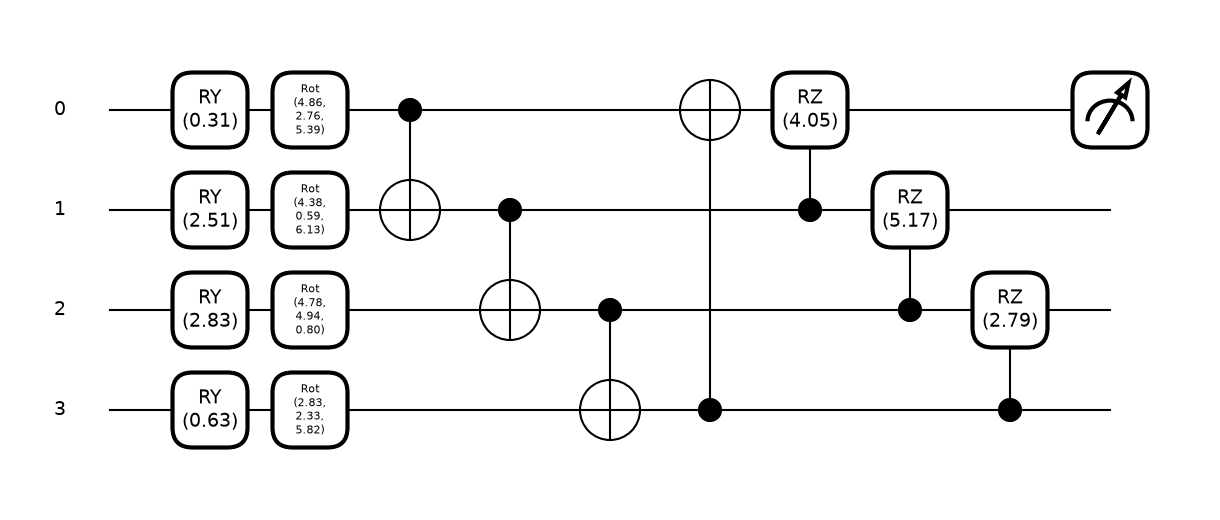

2) Victim VQC (8 qubits): RY/RZ encoding of the 16 features -> 4 StronglyEntanglingLayers -> <Z0>


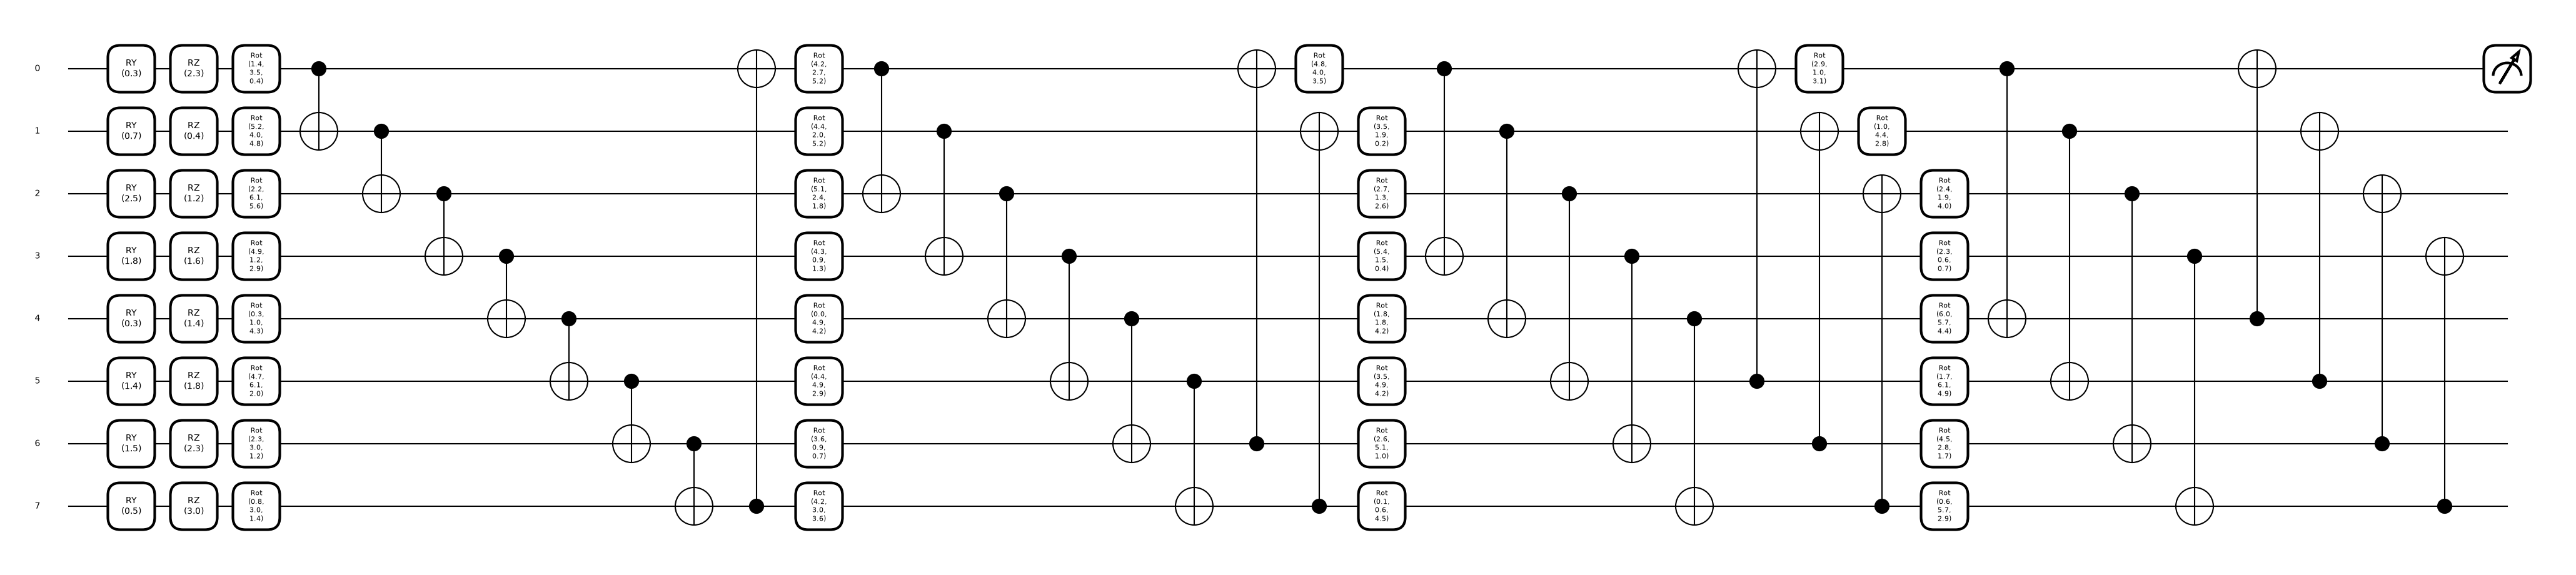

In [11]:
def trojan_qnode(mode, wv, reps=1, depth=1):
    """mode: benign | A | B (ancilla triggered) | B0 (ancilla idle) | C | C0. Returns the QNode that is drawn and checked."""
    n_w = 9 if mode in ("B", "B0", "C", "C0") else 8
    inj = injector_spec(np.random.default_rng(INJ_SEED), reps, depth)
    @qml.qnode(qml.device("default.qubit", wires=n_w))
    def circ(f):
        qml.AngleEmbedding(np.pi / 2 * (f[:8] + 1), wires=range(8), rotation="Y")
        qml.AngleEmbedding(np.pi / 2 * (f[8:] + 1), wires=range(8), rotation="Z")
        if mode in ("B", "C"): qml.PauliX(wires=8)                  # the malicious config file inserts this X on the ancilla
        if mode == "A": apply_spec(inj)
        elif mode in ("B", "B0"): apply_spec(inj, controls=8)
        elif mode in ("C", "C0"): apply_spec(hadamard_spec(), controls=8)
        apply_spec(sel_spec(wv, N_Q))
        if n_w == 9:                                                 # Trojan shield: two cross-connected CNOTs ancilla <-> qubit 7
            qml.CNOT(wires=[8, 7]); qml.CNOT(wires=[7, 8])
        return qml.expval(qml.PauliZ(0))
    return circ

def show_slices(circ, f, title, per_fig=45):
    """Draw the complete gate list of `circ` in consecutive slices; assert that the slices add up to the whole circuit."""
    tape = qml.workflow.construct_batch(circ, level=0)(f)[0][0]
    ops = tape.operations
    slices = [ops[i:i + per_fig] for i in range(0, len(ops), per_fig)]
    assert sum(len(s) for s in slices) == len(ops) and [o for s in slices for o in s] == list(ops)
    for k, s in enumerate(slices):
        sub = qml.tape.QuantumScript(s, [qml.expval(qml.PauliZ(0))])
        fig, ax = qml.drawer.tape_mpl(sub, decimals=1, wire_order=list(range(len(tape.wires))), fontsize=11)
        fig.suptitle(f"{title}: gates {k * per_fig + 1}-{k * per_fig + len(s)} of {len(ops)}", y=1.02, fontsize=11)
        plt.show()
    return len(ops)

f_demo = np.random.default_rng(3).uniform(-1, 1, 16)
wv_demo = np.asarray(wv0)

print("1) Quanvolution filter (4 qubits): RY encoding of one 2x2 patch -> StronglyEntanglingLayers(1) -> 3 pooling CRZ -> <Z0>")
fig, ax = qml.draw_mpl(quanv, level="device", decimals=2)(np.array([0.1, 0.8, 0.9, 0.2]), np.asarray(wq0), np.asarray(pw0)); plt.show()
print("2) Victim VQC (8 qubits): RY/RZ encoding of the 16 features -> 4 StronglyEntanglingLayers -> <Z0>")
fig, ax = qml.draw_mpl(vqc, level="device", decimals=1, fontsize=10)(f_demo, wv_demo); plt.show()

3) Class A Trojan (8 qubits): encoding -> U_1 -> U_1^dagger (noise injector, drawn with reps=1, depth=1) -> VQC


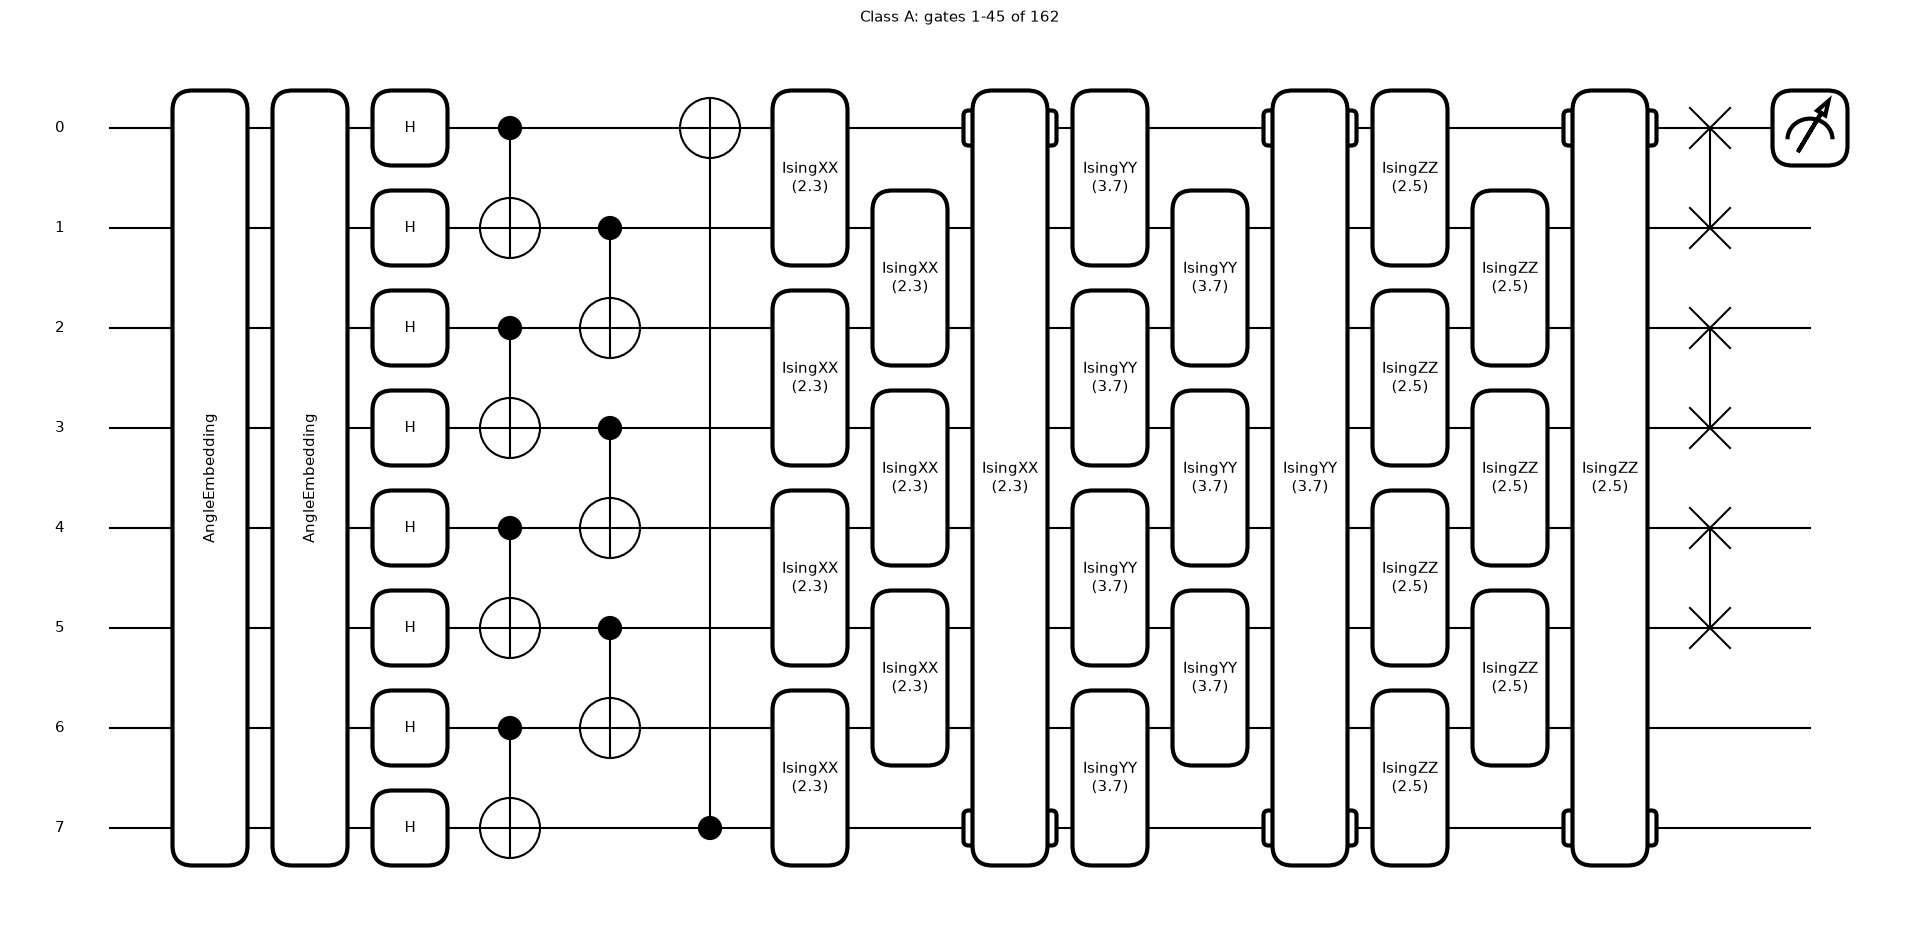

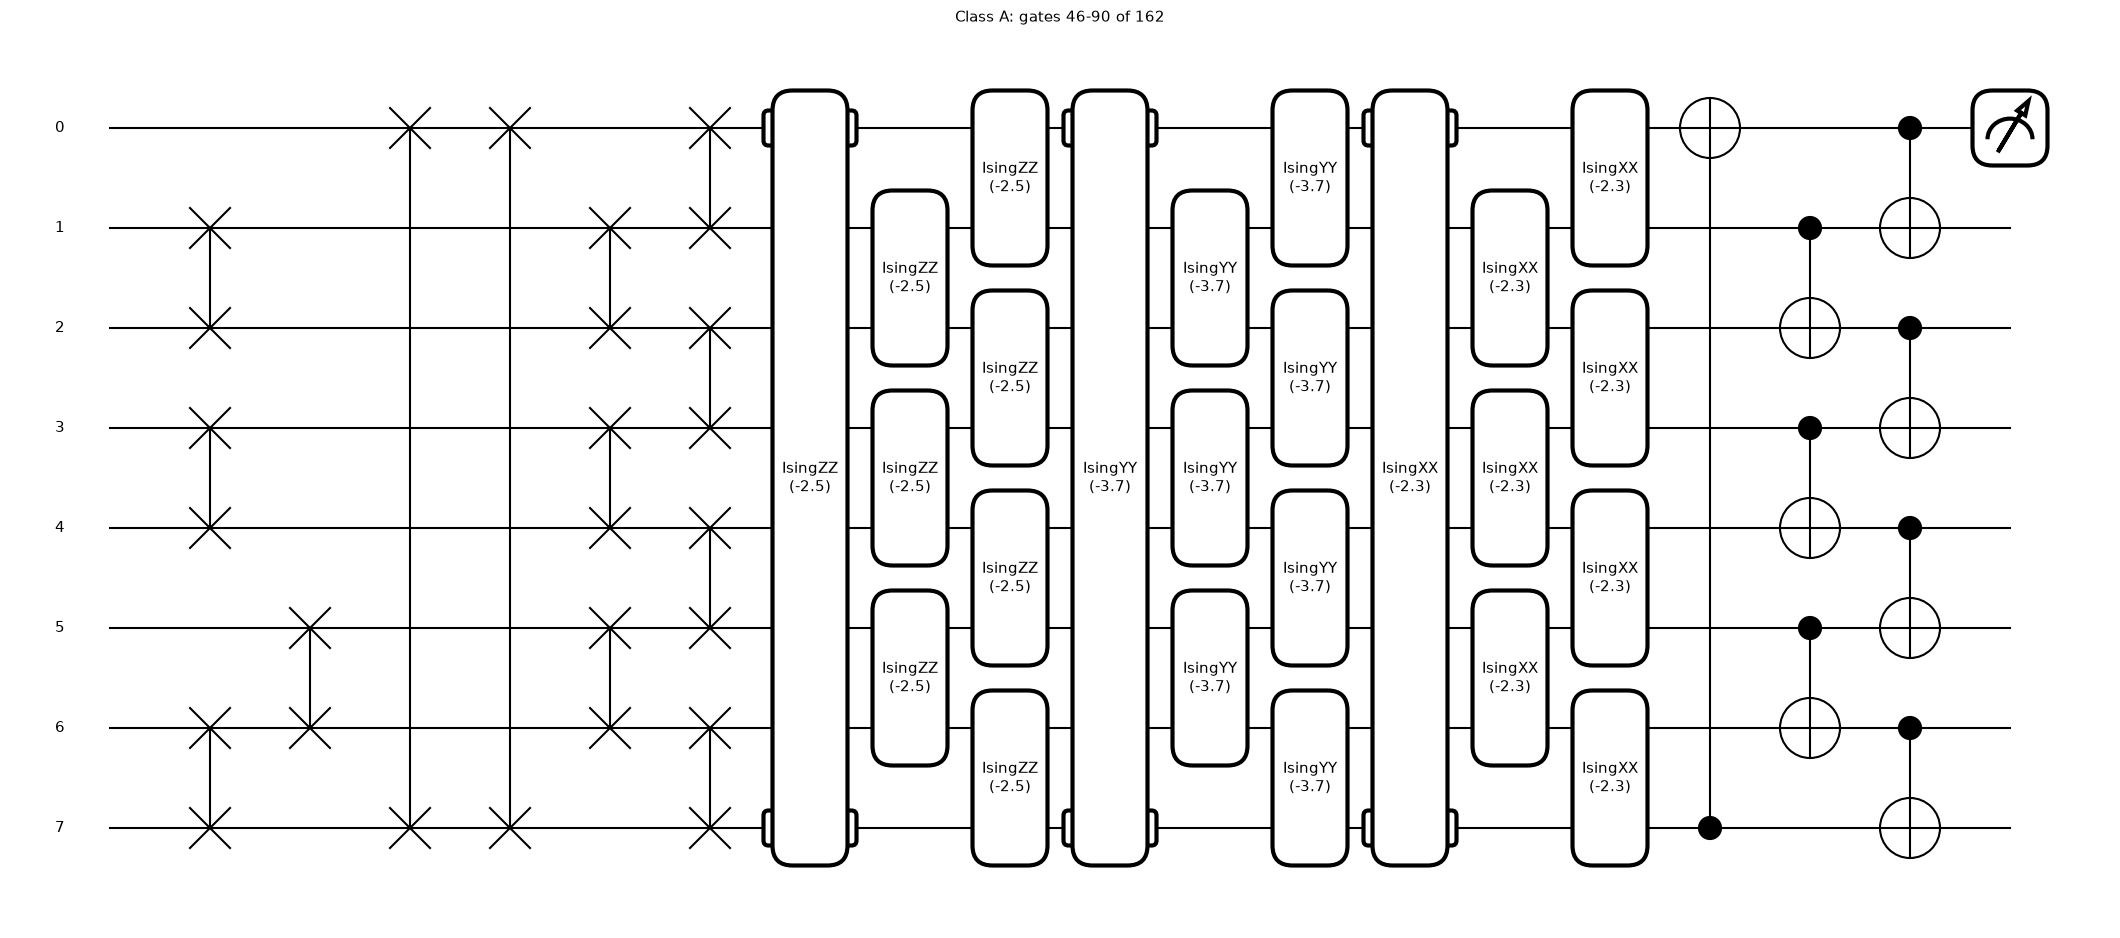

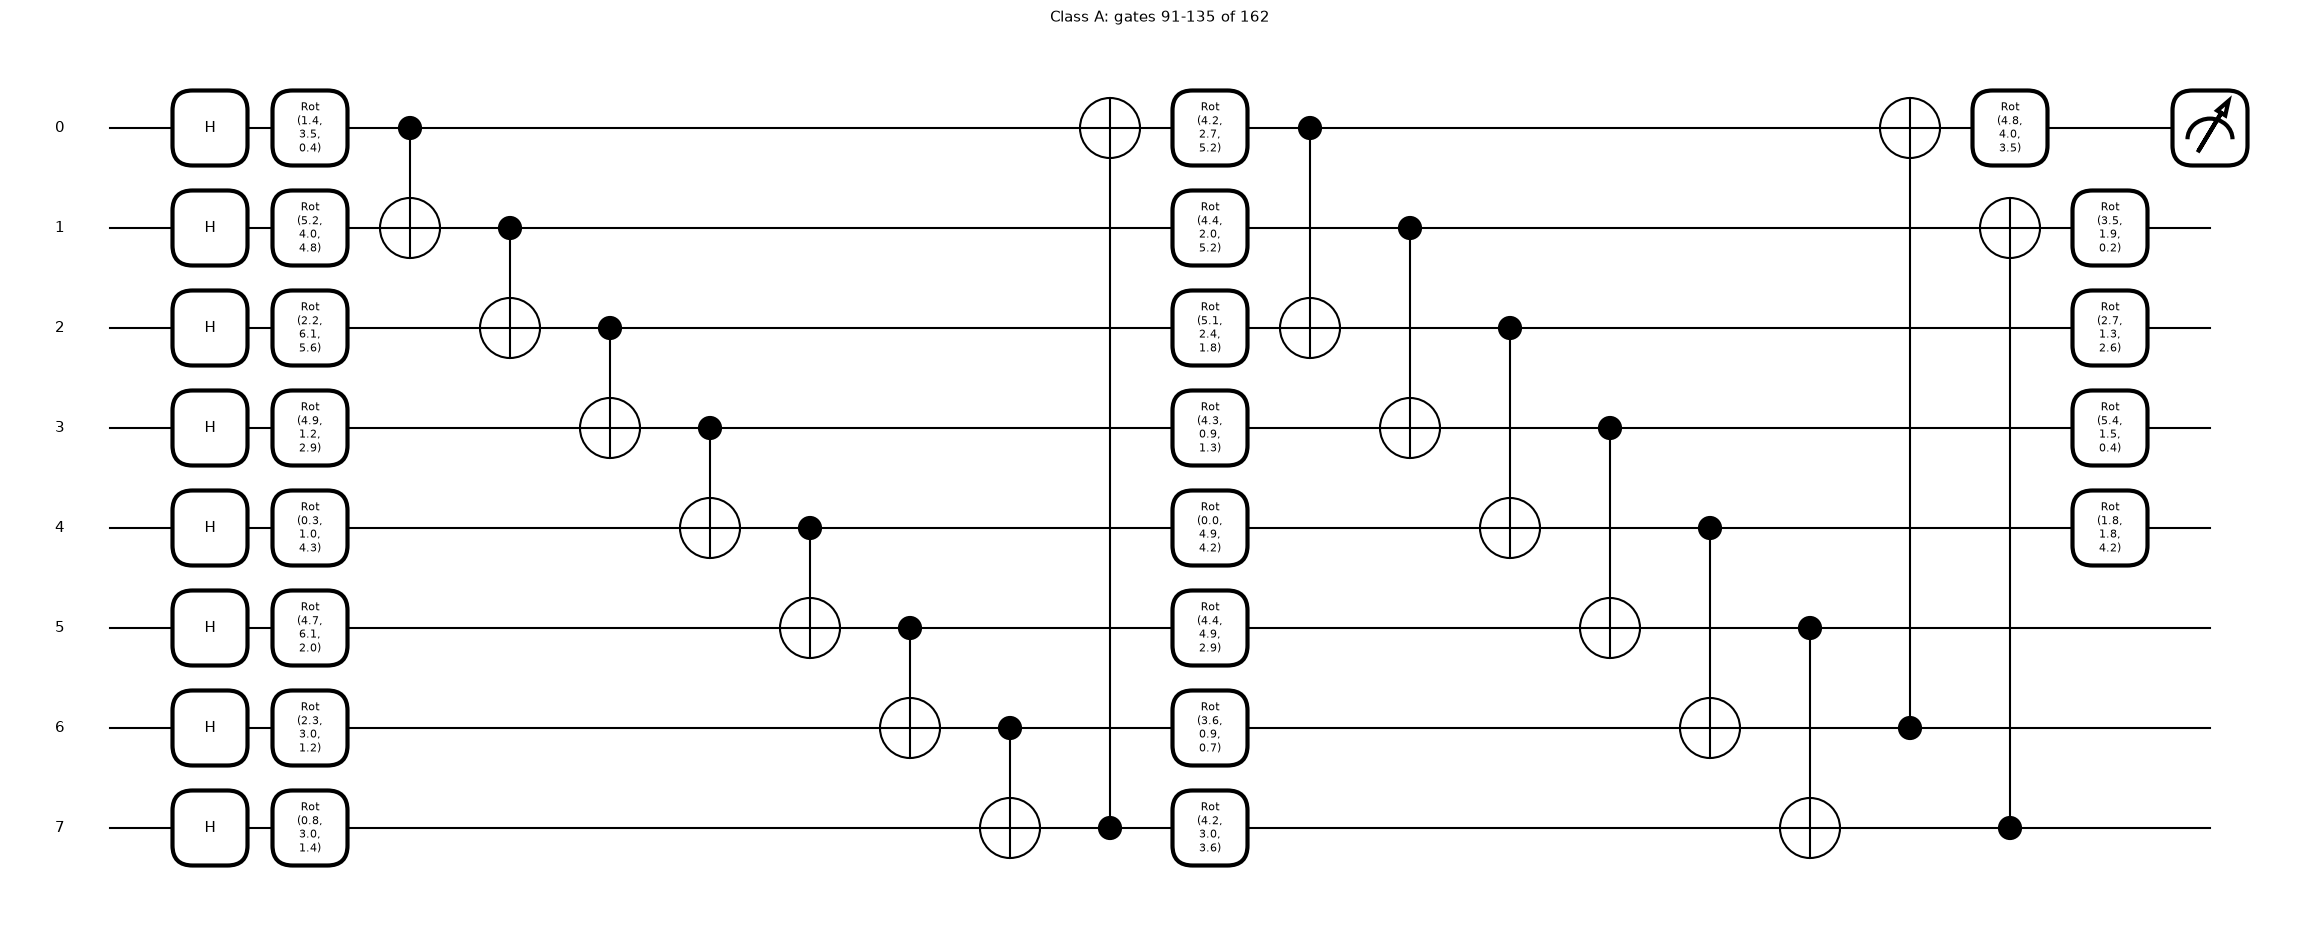

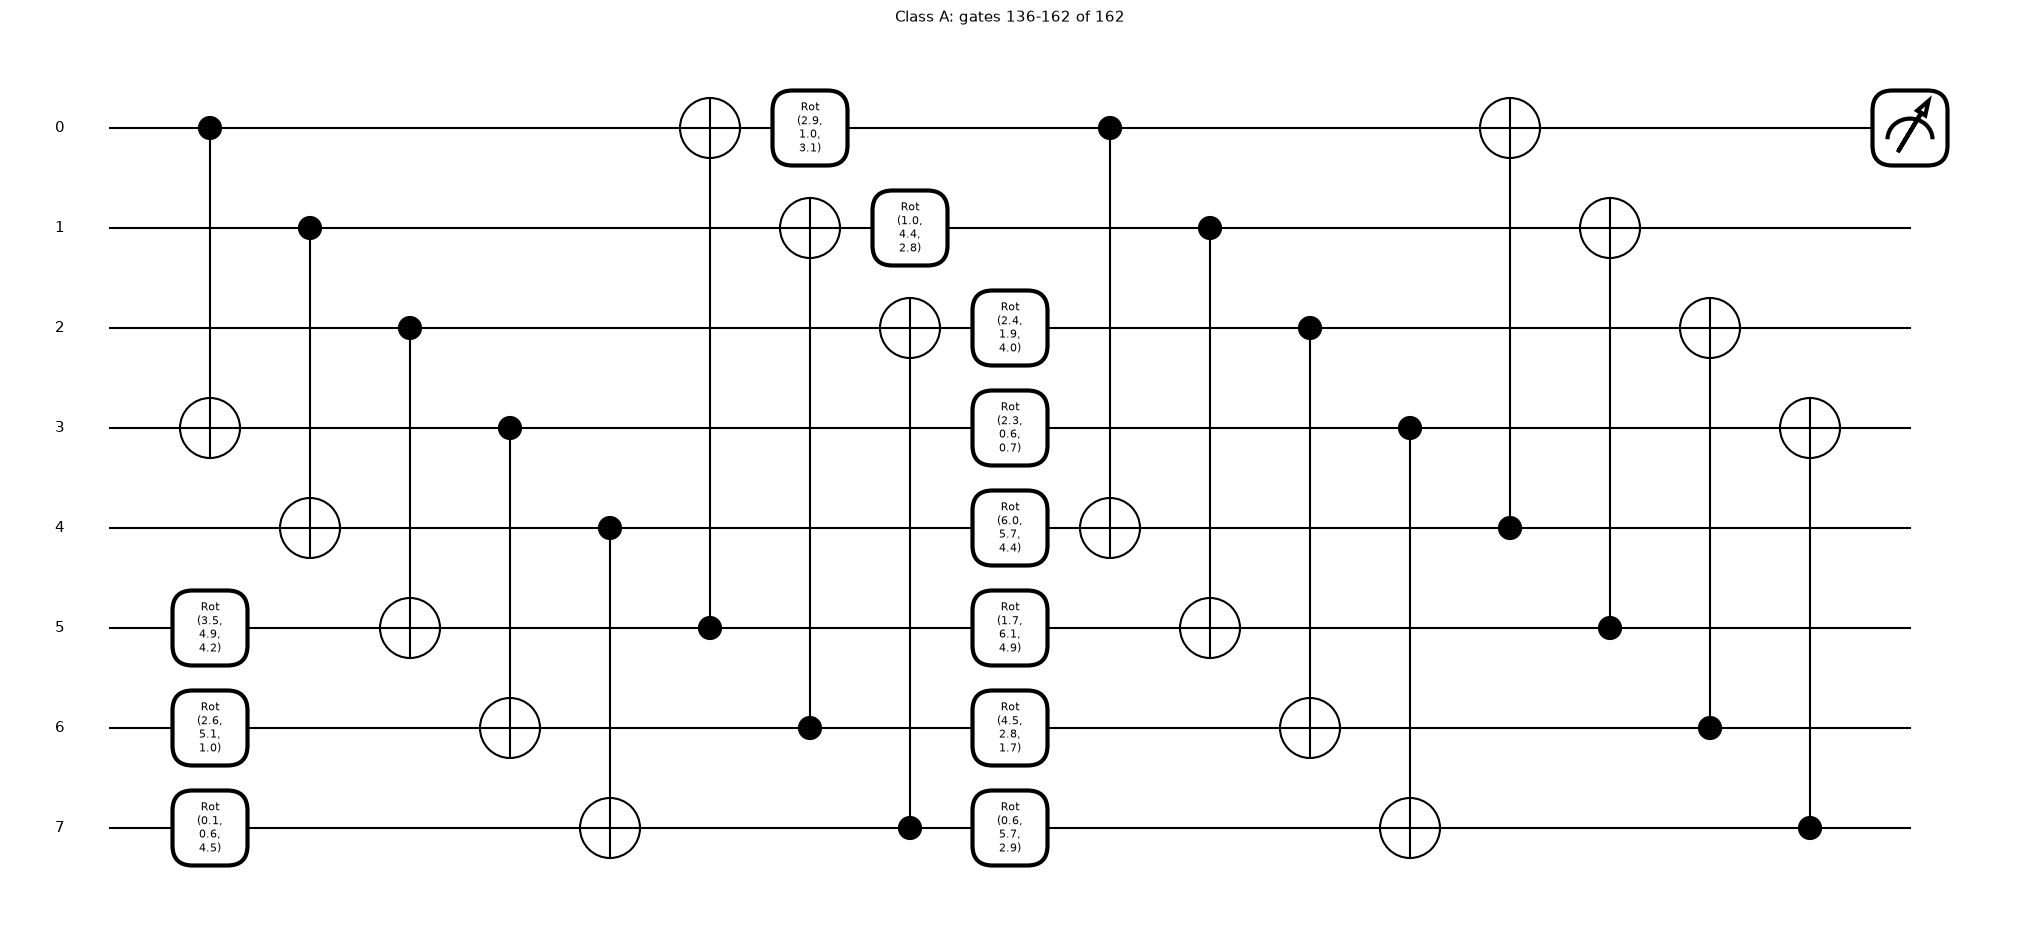

In [12]:
print("3) Class A Trojan (8 qubits): encoding -> U_1 -> U_1^dagger (noise injector, drawn with reps=1, depth=1) -> VQC")
n_ops_A = show_slices(trojan_qnode("A", wv_demo), f_demo, "Class A")

4) Class B Trojan (9 qubits, qubit 8 = ancilla): X trigger -> ancilla-controlled injector -> VQC -> Trojan shield (2 CNOTs)


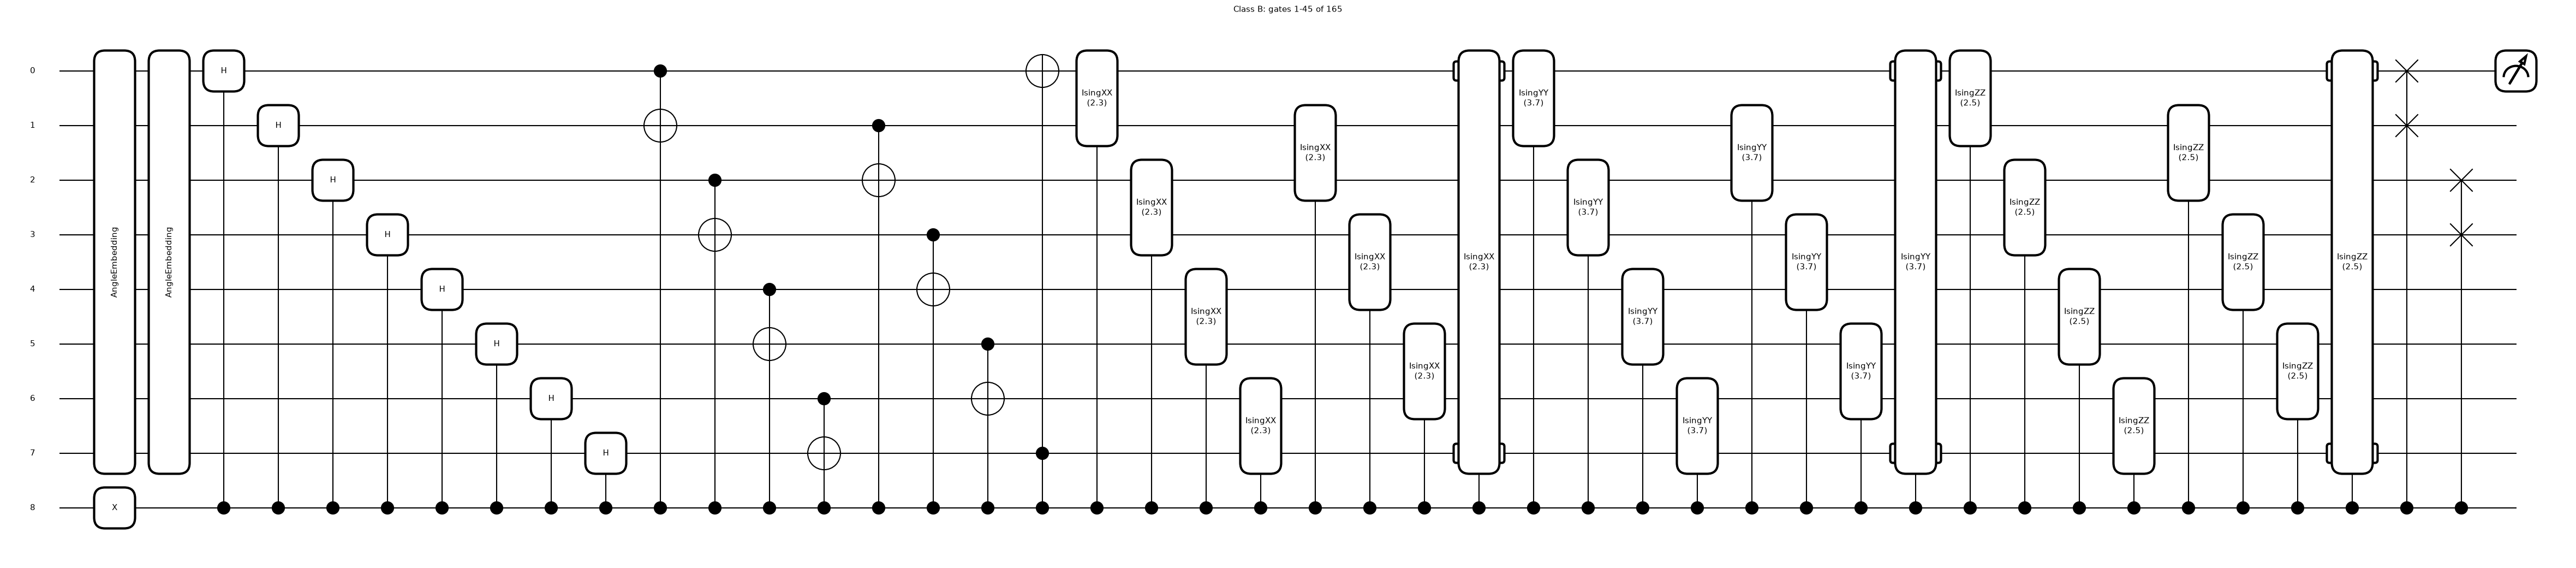

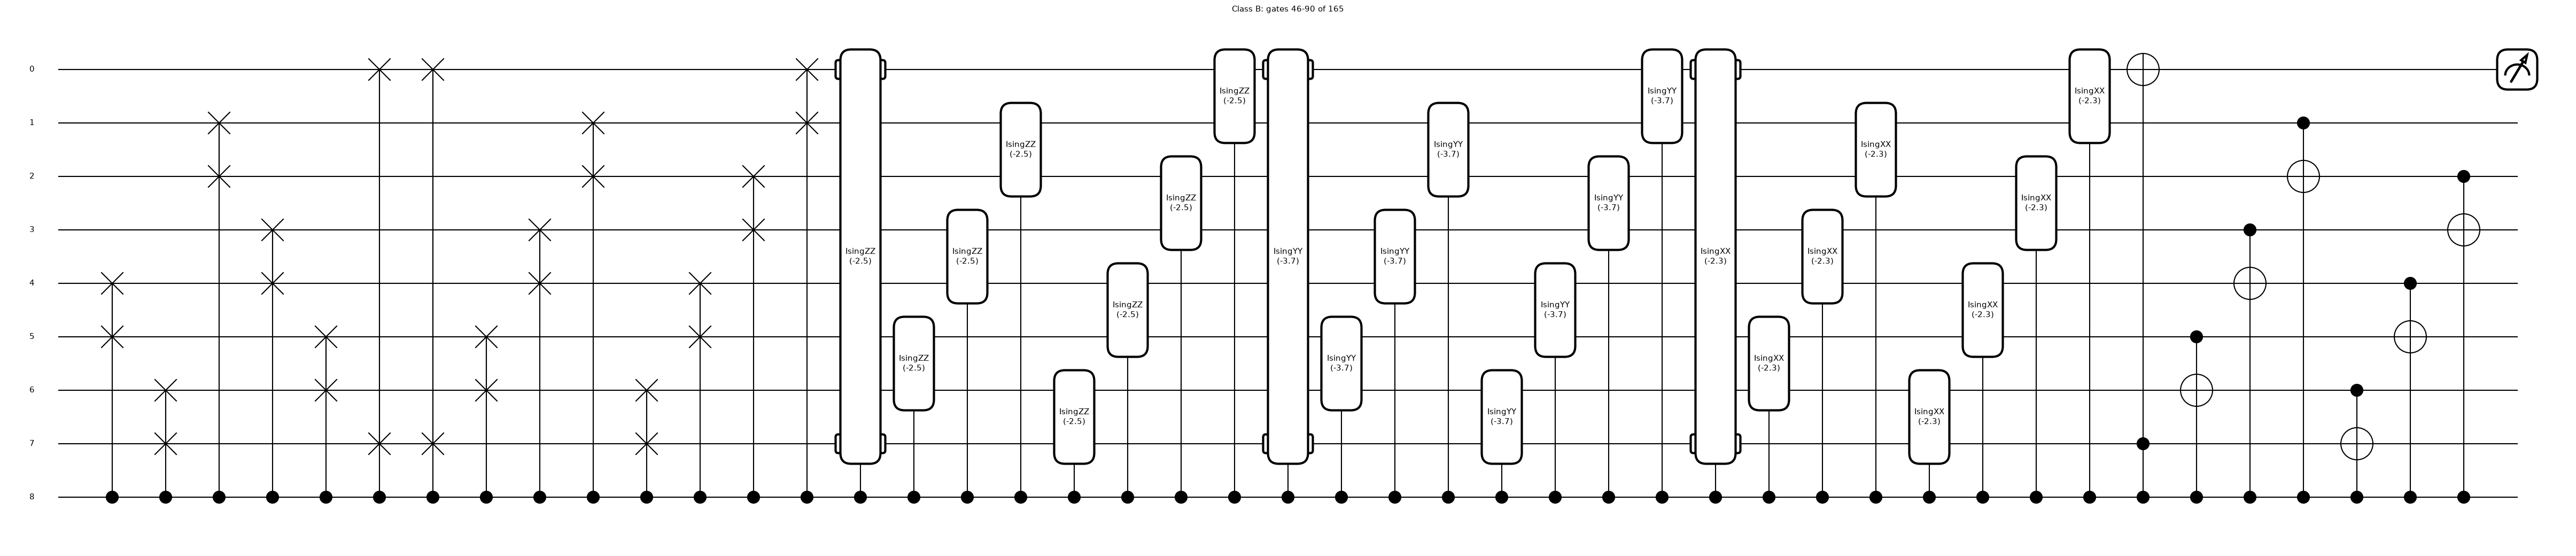

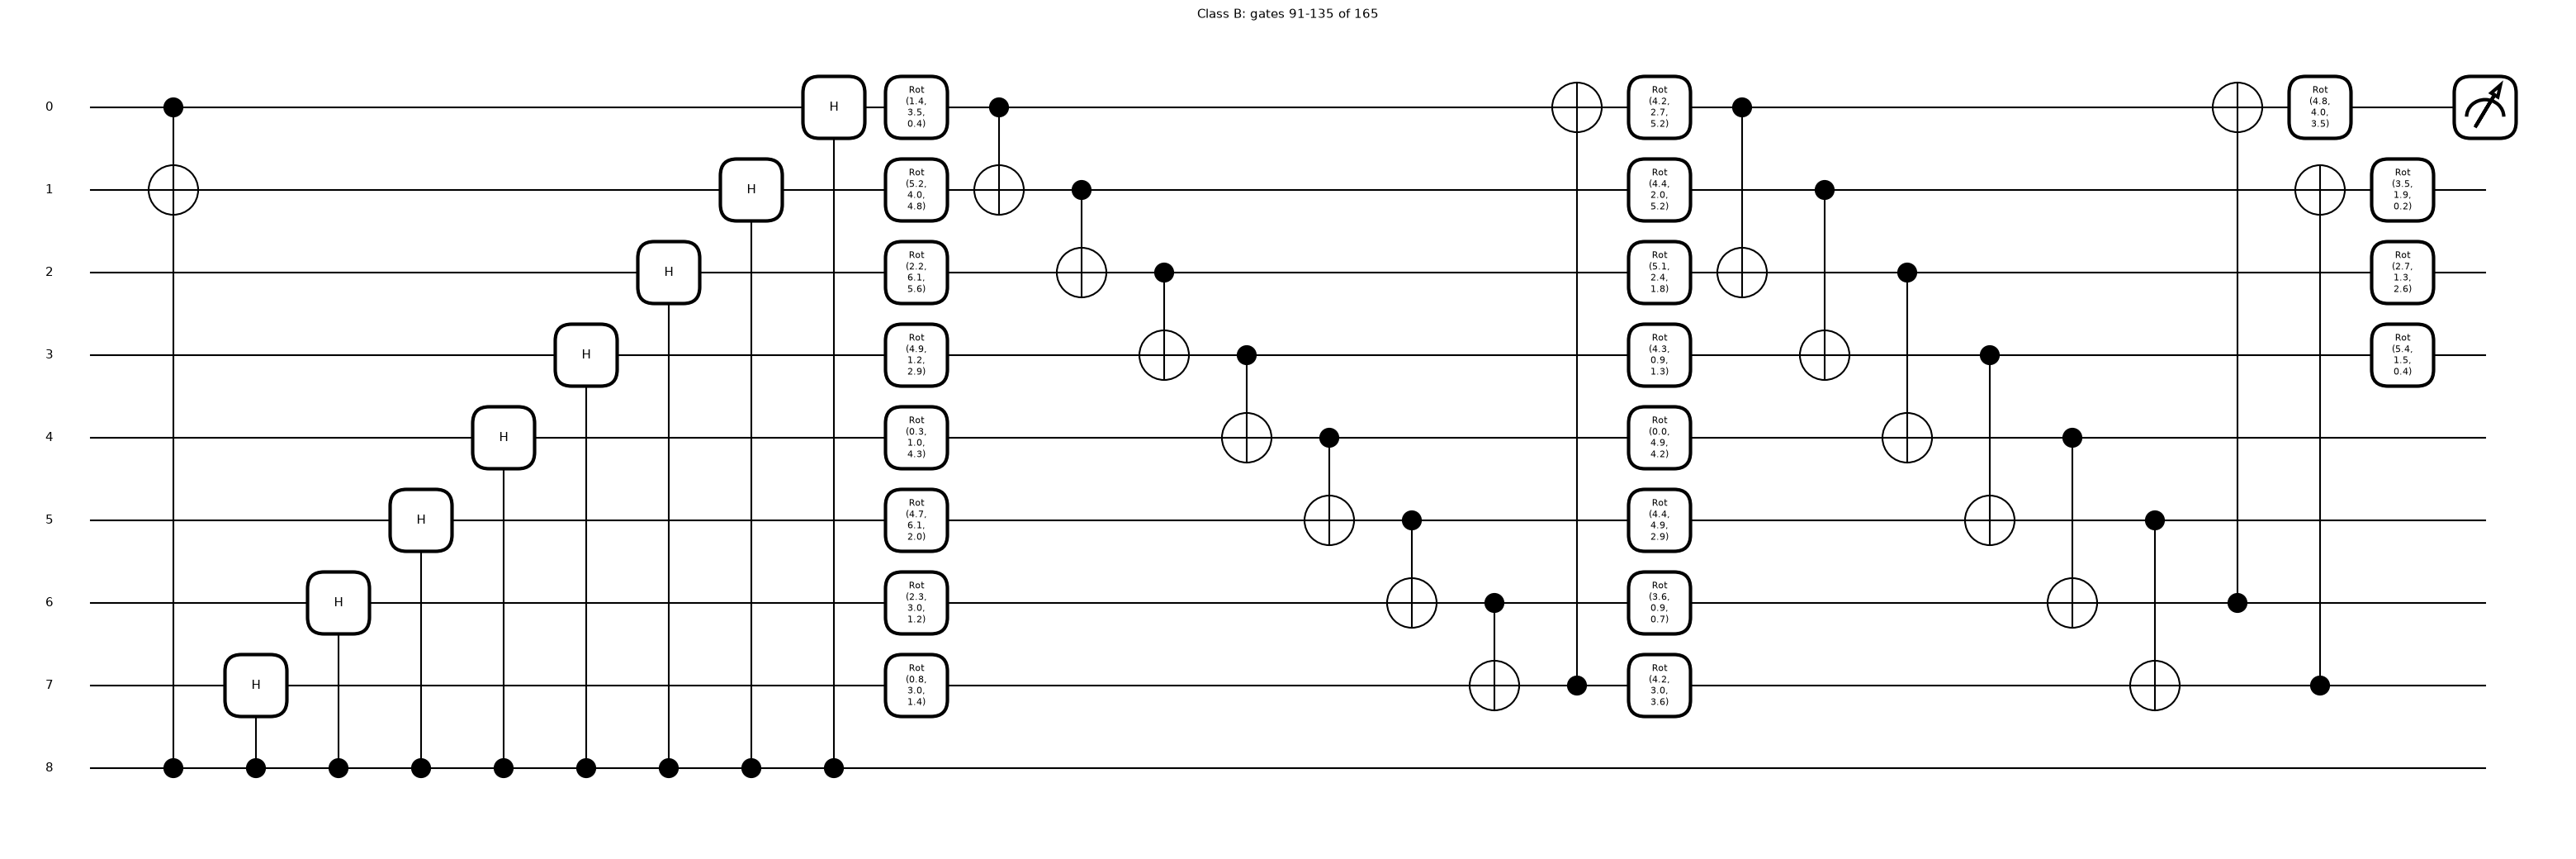

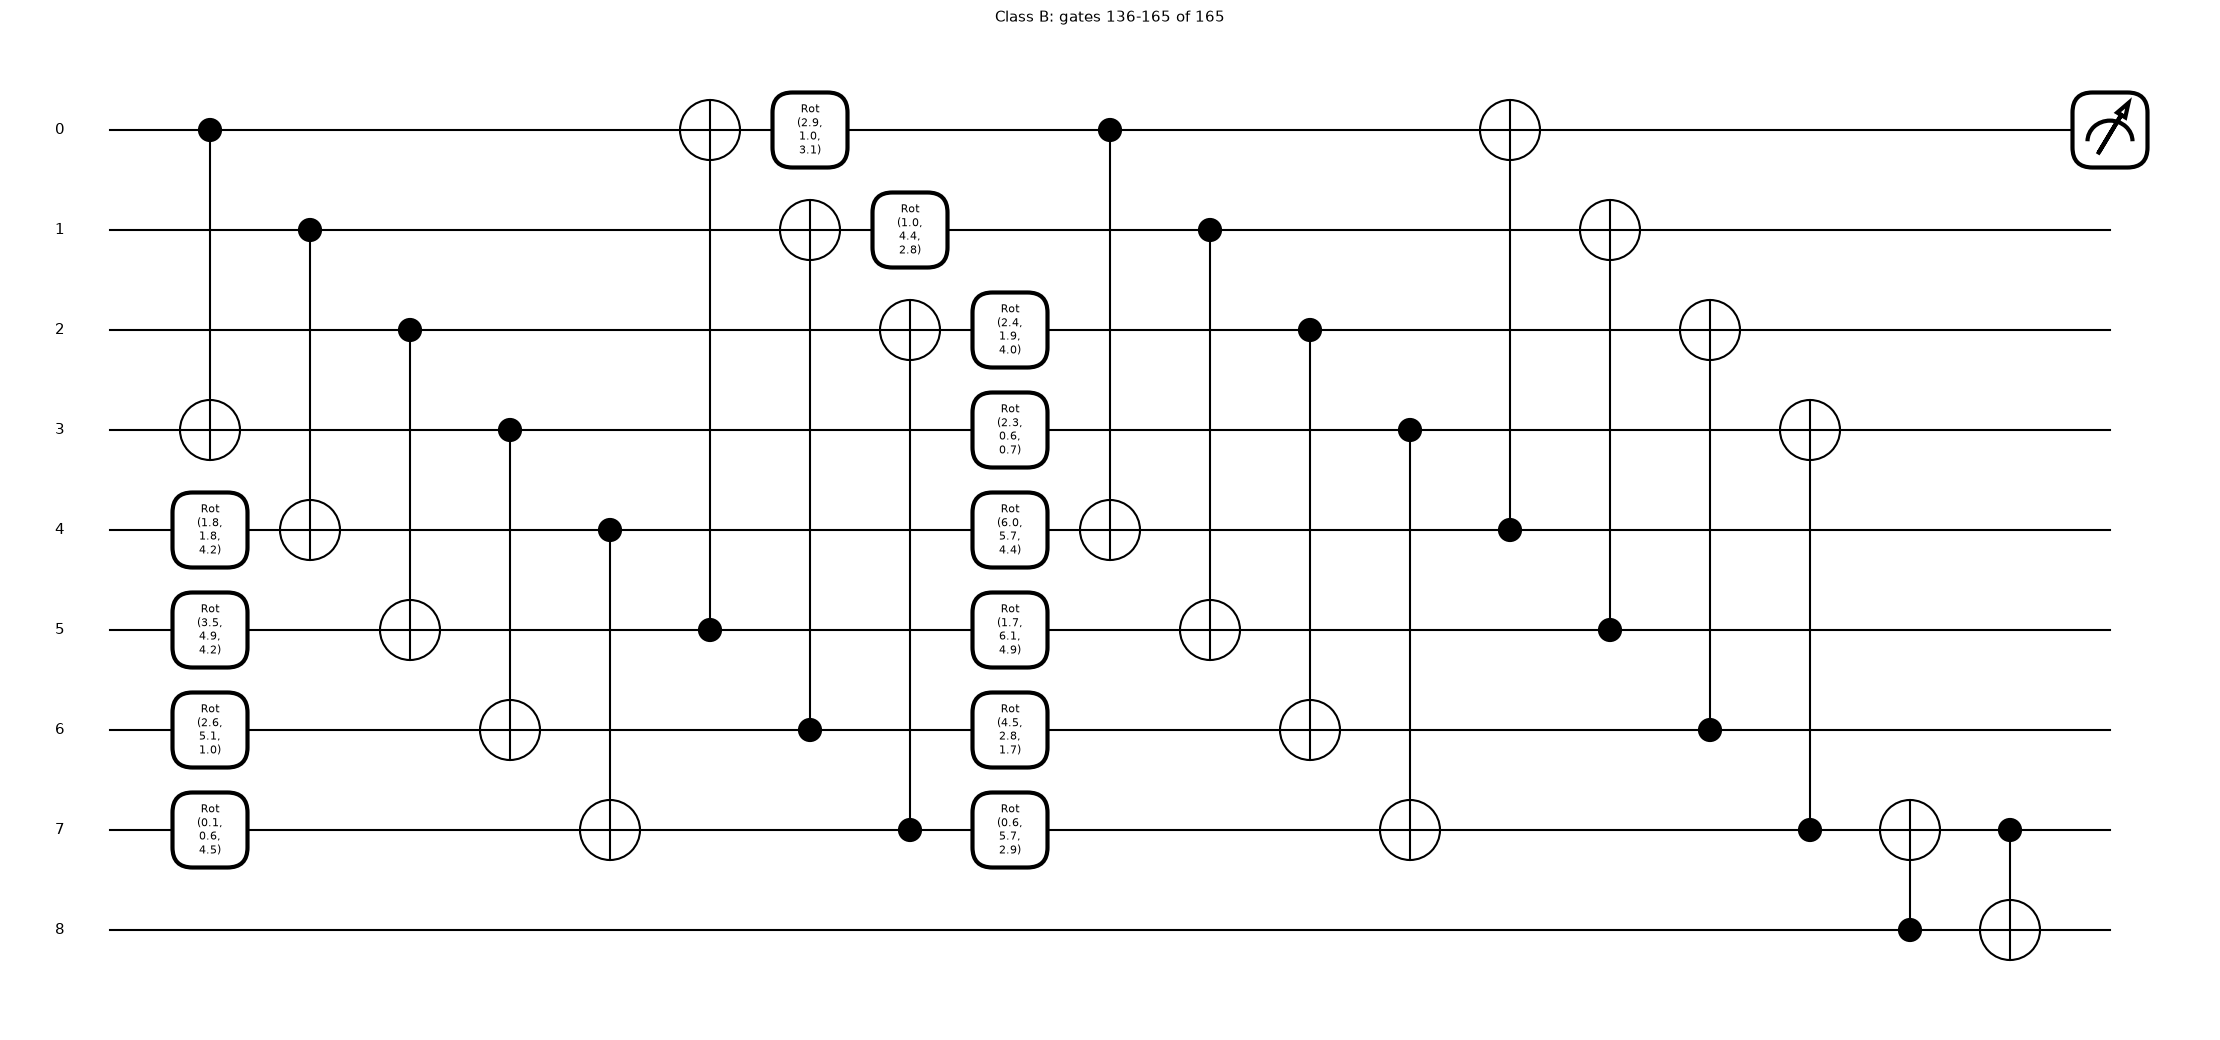

In [13]:
print("4) Class B Trojan (9 qubits, qubit 8 = ancilla): X trigger -> ancilla-controlled injector -> VQC -> Trojan shield (2 CNOTs)")
n_ops_B = show_slices(trojan_qnode("B", wv_demo), f_demo, "Class B")

5) Class C Trojan (9 qubits): X trigger -> 8 ancilla-controlled Hadamards on the encoded state -> VQC -> Trojan shield


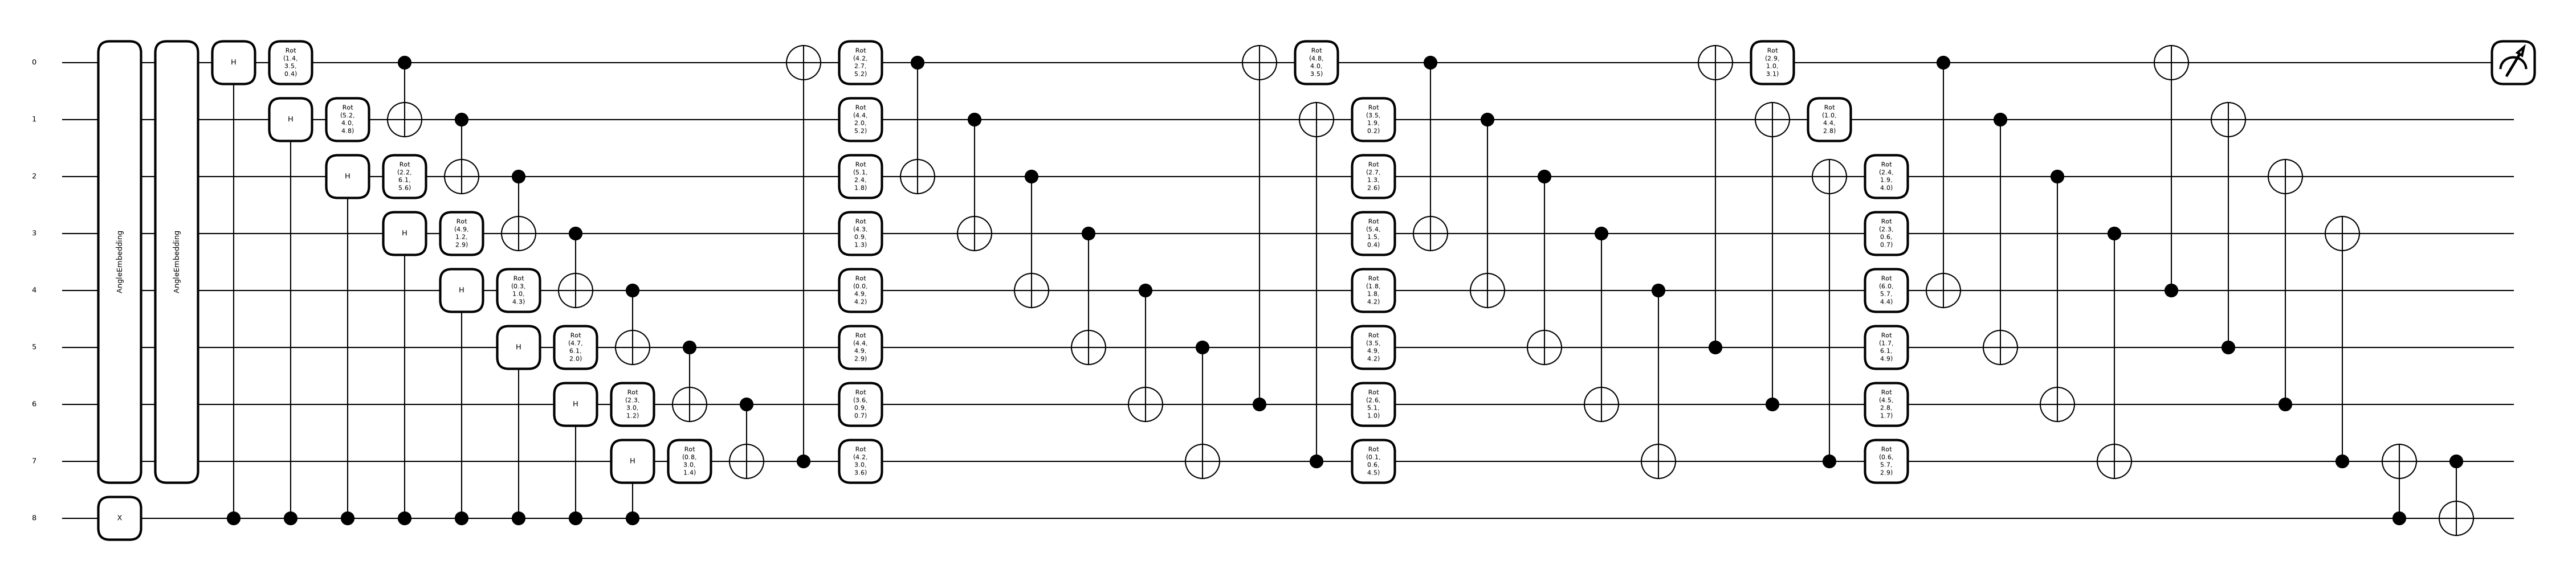

In [14]:
print("5) Class C Trojan (9 qubits): X trigger -> 8 ancilla-controlled Hadamards on the encoded state -> VQC -> Trojan shield")
fig, ax = qml.draw_mpl(trojan_qnode("C", wv_demo), decimals=1, fontsize=9)(f_demo); plt.show()

In [15]:
# ---- qubits / depth / parameters of every architecture, and the size of the Trojans as actually executed
def stats(circ, *args, level=0):
    s = qml.specs(circ, level=level)(*args)
    return s.num_device_wires, s.resources.depth, s.resources.num_gates

rows = []
q, d, g = stats(quanv, np.array([0.1, 0.8, 0.9, 0.2]), np.asarray(wq0), np.asarray(pw0), level="device")
rows.append(["quanvolution filter + pooling", q, d, g, wq0.size + pw0.size])
q, d, g = stats(vqc, f_demo, wv_demo, level="device")
rows.append(["victim VQC", q, d, g, wv0.size])
for mode, label in (("A", "VQC + Class A (executed: depth 3, %d blocks)" % INJ_REPS), ("B", "VQC + Class B (executed: depth 3, %d blocks)" % INJ_REPS),
                    ("C", "VQC + Class C (8 controlled H)")):
    q, d, g = stats(trojan_qnode(mode, wv_demo, reps=INJ_REPS, depth=INJ_DEPTH), f_demo)
    rows.append([label, q, d, g, wv0.size])
arch = pd.DataFrame(rows, columns=["circuit", "qubits", "depth", "gates (PennyLane level 0 / device)", "trainable parameters"])
display(arch)
print("whole victim: %d trainable parameters (quanvolution 12 + pooling 3 + VQC 96); the Trojans add no trainable parameters." % (wq0.size + pw0.size + wv0.size))

# ---- ideal-simulator checks of the Trojan logic (PennyLane default.qubit, exact)
ref = lambda f: vqc(f, wv_demo)                                                      # the trained VQC QNode
fs = np.random.default_rng(11).uniform(-1, 1, (6, 16))
def run(circ): return np.array([circ(f) for f in fs])
z_ref = np.array([ref(f) for f in fs])
z_ben = run(trojan_qnode("benign", wv_demo))
z_A, z_B, z_B0, z_C0 = (run(trojan_qnode(m, wv_demo, reps=2, depth=INJ_DEPTH)) for m in ("A", "B", "B0", "C0"))
z_C = run(trojan_qnode("C", wv_demo))
@qml.qnode(qml.device("default.qubit", wires=N_Q))
def c_prefix(f):
    qml.AngleEmbedding(np.pi / 2 * (f[:8] + 1), wires=range(8), rotation="Y"); qml.AngleEmbedding(np.pi / 2 * (f[8:] + 1), wires=range(8), rotation="Z")
    apply_spec(hadamard_spec()); apply_spec(sel_spec(wv_demo, N_Q)); return qml.expval(qml.PauliZ(0))
z_Cp = run(c_prefix)
print(f"spec-built benign circuit  vs the trained `vqc` QNode : max diff {np.abs(z_ben - z_ref).max():.1e}")
print(f"Class A  (2 blocks, ideal) vs benign                  : max diff {np.abs(z_A - z_ben).max():.1e}   (U^dagger U = I)")
print(f"Class B  triggered (ideal) vs benign                  : max diff {np.abs(z_B - z_ben).max():.1e}")
print(f"Class B  dormant (ancilla |0>)  vs benign             : max diff {np.abs(z_B0 - z_ben).max():.1e}")
print(f"Class C  dormant (ancilla |0>)  vs benign             : max diff {np.abs(z_C0 - z_ben).max():.1e}   (Trojan shield changes nothing either)")
print(f"Class C  triggered vs benign                          : mean |diff| {np.abs(z_C - z_ben).mean():.3f}   (the output is scrambled)")
print(f"Class C  triggered (9 qubits) vs plain H^8 prefix     : max diff {np.abs(z_C - z_Cp).max():.1e}")
assert np.abs(z_ben - z_ref).max() < 1e-9 and np.abs(z_A - z_ben).max() < 1e-9 and np.abs(z_B - z_ben).max() < 1e-9
assert np.abs(z_B0 - z_ben).max() < 1e-9 and np.abs(z_C0 - z_ben).max() < 1e-9 and np.abs(z_C - z_Cp).max() < 1e-9 and np.abs(z_C - z_ben).mean() > 0.01

,circuit,qubits,depth,gates (PennyLane level 0 / device),trainable parameters
0,quanvolution filter + pooling,4,9,15,15
1,victim VQC,8,23,80,96
2,"VQC + Class A (executed: depth 3, 50 blocks)",8,3123,12866,96
3,"VQC + Class B (executed: depth 3, 50 blocks)",9,12824,12869,96
4,VQC + Class C (8 controlled H),9,26,77,96


whole victim: 111 trainable parameters (quanvolution 12 + pooling 3 + VQC 96); the Trojans add no trainable parameters.


spec-built benign circuit  vs the trained `vqc` QNode : max diff 1.7e-16
Class A  (2 blocks, ideal) vs benign                  : max diff 7.8e-16   (U^dagger U = I)
Class B  triggered (ideal) vs benign                  : max diff 1.0e-15
Class B  dormant (ancilla |0>)  vs benign             : max diff 1.1e-16
Class C  dormant (ancilla |0>)  vs benign             : max diff 1.1e-16   (Trojan shield changes nothing either)
Class C  triggered vs benign                          : mean |diff| 0.054   (the output is scrambled)
Class C  triggered (9 qubits) vs plain H^8 prefix     : max diff 2.2e-16


## 4. Training the victim

Training follows Table I: Adam, binary cross-entropy, batch 64, learning rate multiplied by `GAMMA = 0.75` every `STEP_SIZE = 10` epochs
(a PyTorch-style `StepLR`). Gradients come from PennyLane's back-propagation through the exact `default.qubit` simulation; no shots are used
in training (the paper does not say whether it used any). The validation images are only monitored, never used to choose anything.

In the full run the first victim, `paper-config`, uses exactly the paper's learning rate `1e-4` for 100 epochs. With such a small learning rate the
weights stay close to their random initialisation, which probably explains the paper's low benign accuracy (70 %, recall 0.40). Two further
victims with learning rate `1e-2` show what a well-trained network of the same architecture does under attack.

training paper-config: seed 42, lr 0.0001, 100 epochs, 2000 images, batch 64


  [paper-config] epoch   1/100  loss 0.6868  val acc 0.580  (22 s)


  [paper-config] epoch  20/100  loss 0.6720  val acc 0.645  (501 s)


  [paper-config] epoch  40/100  loss 0.6604  val acc 0.675  (1039 s)


  [paper-config] epoch  60/100  loss 0.6538  val acc 0.685  (1586 s)


...

  [lr1e-2-b] epoch   4/12  loss 0.4016  val acc 0.905  (90 s)


  [lr1e-2-b] epoch   6/12  loss 0.3792  val acc 0.920  (140 s)


  [lr1e-2-b] epoch   8/12  loss 0.3711  val acc 0.940  (187 s)


  [lr1e-2-b] epoch  10/12  loss 0.3585  val acc 0.935  (241 s)


  [lr1e-2-b] epoch  12/12  loss 0.3554  val acc 0.945  (289 s)


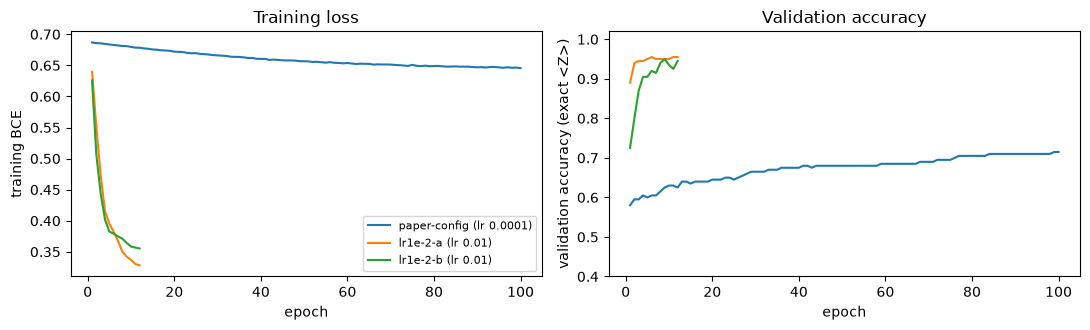

In [16]:
def train_victim(name, seed, lr, epochs):
    wq, pw, wv = init_params(seed)
    opt = qml.AdamOptimizer(stepsize=lr)
    r = np.random.default_rng(seed)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        opt.stepsize = lr * GAMMA ** (ep // STEP_SIZE)                       # StepLR(step_size=10, gamma=0.75)
        perm, losses = r.permutation(len(img_train)), []
        for s in range(0, len(perm), BATCH):
            ib = perm[s:s + BATCH]; xb, yb = img_train[ib], y_train[ib].astype(float)
            (wq, pw, wv), l = opt.step_and_cost(lambda a, b, c: bce(model(a, b, c, xb), yb), wq, pw, wv)
            losses.append(float(l))
        zv = np.asarray(model(wq, pw, wv, img_val))
        hist.append((ep + 1, float(np.mean(losses)), float(((zv < 0).astype(int) == y_val).mean())))
        if ep == 0 or (ep + 1) % max(1, epochs // 5) == 0 or ep + 1 == epochs:
            print(f"  [{name}] epoch {ep + 1:3d}/{epochs}  loss {hist[-1][1]:.4f}  val acc {hist[-1][2]:.3f}  ({time.time() - t0:.0f} s)")
    return dict(name=name, seed=seed, lr=lr, epochs=epochs, params=(np.asarray(wq), np.asarray(pw), np.asarray(wv)), hist=np.array(hist), train_time=time.time() - t0)

victims = []
for (nm, sd, lr, ep) in VICTIMS:
    print(f"training {nm}: seed {sd}, lr {lr}, {ep} epochs, {len(img_train)} images, batch {BATCH}")
    victims.append(train_victim(nm, sd, lr, ep))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for v in victims:
    ax[0].plot(v["hist"][:, 0], v["hist"][:, 1], label=f'{v["name"]} (lr {v["lr"]:g})'); ax[1].plot(v["hist"][:, 0], v["hist"][:, 2], label=v["name"])
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training BCE"); ax[0].set_title("Training loss"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (exact <Z>)"); ax[1].set_title("Validation accuracy"); ax[1].set_ylim(0.4, 1.02)
plt.tight_layout(); plt.show()

## 5. Clean-model baselines

The Trojans are circuit-level and have no classical counterpart, but a fair reference for the *benign* accuracy is a classical model on exactly the
quantum model's input. RandomForest and RBF-SVC are trained (training split only) on the 16 quanvolution features of the main victim
and, for context, on the 64 down-sampled pixels. All use the ideal simulator.

,model,input,test acc (%),precision,recall,F1,time (s)
0,RandomForest,16 quanvolution features,98.5,0.980,0.99,0.985,0.803
1,SVC (rbf),16 quanvolution features,99.5,0.990,1.00,0.995,0.078
2,RandomForest,64 pixels (8x8),100.0,1.000,1.00,1.000,0.769
3,SVC (rbf),64 pixels (8x8),100.0,1.000,1.00,1.000,0.051
4,"QNN victim 'paper-config' (ideal, exact <Z>)",8x8 image,70.5,0.629,1.00,0.772,2640.368


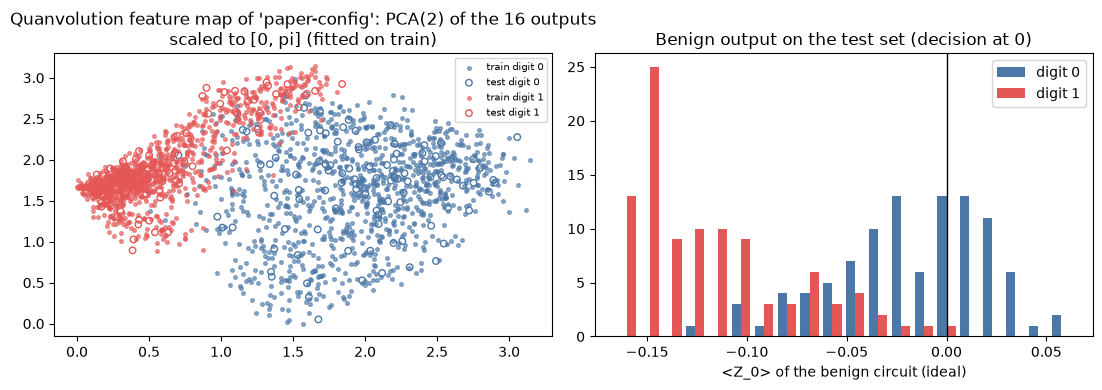

In [17]:
def feats_ideal(imgs, params):
    wq, pw, _ = params
    p = patches(imgs); B = p.shape[0]
    return np.asarray(quanv(p.reshape(B * 16, 4), wq, pw)).reshape(B, 16)

main = victims[0]
F_tr, F_te = feats_ideal(img_train, main["params"]), feats_ideal(img_test, main["params"])
P_tr, P_te = img_train.reshape(len(img_train), -1), img_test.reshape(len(img_test), -1)
base_rows = []
for inp, (Xa, Xb) in {"16 quanvolution features": (F_tr, F_te), "64 pixels (8x8)": (P_tr, P_te)}.items():
    for nm, clf in (("RandomForest", RandomForestClassifier(n_estimators=100, random_state=SEED)), ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED))):
        t0 = time.time(); clf.fit(Xa, y_train); pred = clf.predict(Xb)
        base_rows.append([nm, inp, 100 * accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0), recall_score(y_test, pred, zero_division=0),
                          f1_score(y_test, pred, zero_division=0), time.time() - t0])
zt = np.asarray(model(*main["params"], img_test)); pred_q = (zt < 0).astype(int)
base_rows.append([f"QNN victim '{main['name']}' (ideal, exact <Z>)", "8x8 image", 100 * accuracy_score(y_test, pred_q), precision_score(y_test, pred_q, zero_division=0),
                  recall_score(y_test, pred_q, zero_division=0), f1_score(y_test, pred_q, zero_division=0), main["train_time"]])
baselines = pd.DataFrame(base_rows, columns=["model", "input", "test acc (%)", "precision", "recall", "F1", "time (s)"])
display(baselines.round(3))

# the trained quantum feature map of the main victim: real test/training images as 16-D points, PCA to 2-D, scaled to [0, pi]
pca_f = PCA(n_components=2, random_state=SEED).fit(F_tr)
mm_f = MinMaxScaler((0, np.pi)).fit(pca_f.transform(F_tr))
g_tr, g_te = mm_f.transform(pca_f.transform(F_tr)), np.clip(mm_f.transform(pca_f.transform(F_te)), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for d_ in (0, 1):
    ax[0].scatter(g_tr[y_train == d_, 0], g_tr[y_train == d_, 1], s=7, alpha=.6, c=cols[d_], label=f"train digit {d_}")
    ax[0].scatter(g_te[y_test == d_, 0], g_te[y_test == d_, 1], s=22, facecolors="none", edgecolors=cols[d_], label=f"test digit {d_}")
ax[0].set_title(f"Quanvolution feature map of '{main['name']}': PCA(2) of the 16 outputs\nscaled to [0, pi] (fitted on train)"); ax[0].legend(fontsize=7)
ax[1].hist([zt[y_test == 0], zt[y_test == 1]], bins=20, color=[cols[0], cols[1]], label=["digit 0", "digit 1"])
ax[1].axvline(0, color="k", lw=1); ax[1].set_xlabel("<Z_0> of the benign circuit (ideal)"); ax[1].set_title("Benign output on the test set (decision at 0)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Mounting the QuPT attacks

For every trained victim and every environment the notebook computes `O_eff` for the benign circuit, for Class A/B (the injector pushed
through the circuit) and for Class C (the Hadamard layer), then the expectation `<Z_0>` for each of the 200 test images. The network's convolution and
pooling stages are simulated in the same environment (noisy or ideal). Every reported metric uses a **1024-shot estimate** of `<Z_0>`
(a binomial draw with a fixed seed, the same for every attack of one victim and environment, so that an attack that does not change `<Z_0>` changes no prediction): the predicted class is 1 (digit "1") when the estimate is negative, and its negative is the score for the AUC.
In the ideal environment the injector is pushed through only 5 blocks (an exact identity check; the effect of more blocks is the same). The "Impact (%)" columns are `(benign - attacked) / benign x 100`, as in the paper. In the ideal environment Class A/B must be exactly the identity, which is asserted.

In [18]:
ENVS = {"Ideal": (0.0, 0.0), "IonQ Aria-1 (depolarising)": (R1Q, R2Q)}
ATTACKS = ["None", "A, B", "C"]

def feats_engine(imgs, params, r1, r2):
    wq, pw, _ = params
    Oq = heisenberg(quanv_post_spec(wq, pw), N_C, z0_obs(N_C), r1, r2)
    p = patches(imgs).reshape(-1, N_C)
    return expectations(product_states(np.pi * p, np.zeros_like(p)), Oq).reshape(len(imgs), 16)

def metrics_from(zhat, y):
    pred = (zhat < 0).astype(int); score = -zhat
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return dict(acc=100 * accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), auc=roc_auc_score(y, score), cm=cm, score=score)

def shot_estimate(z, seed_tuple):
    r = np.random.default_rng(seed_tuple)
    k = r.binomial(SHOTS, np.clip((1 + z) / 2, 0, 1))
    return (2 * k - SHOTS) / SHOTS

def evaluate_victim(vi, v):
    params = v["params"]; wv = params[2]; out, sweep, timing = {}, {}, {}
    for ei, (env, (r1, r2)) in enumerate(ENVS.items()):
        t0 = time.time()
        f = feats_engine(img_test, params, r1, r2); a, b = vqc_angles(f); psi = product_states(a, b)
        O_vqc = heisenberg(sel_spec(wv, N_Q), N_Q, z0_obs(N_Q), r1, r2)
        reps_max = max(SWEEP_REPS + [INJ_REPS]) if r1 > 0 else min(INJ_REPS, 5)      # ideal case: U^dagger U = I, a 5-block check suffices
        inj = injector_spec(np.random.default_rng(INJ_SEED), reps_max, INJ_DEPTH)
        block = len(inj) // reps_max; snaps = {}
        heisenberg(inj, N_Q, O_vqc, r1, r2, snapshots=snaps, snap_every=block)            # snaps[k]: injector of the last k blocks
        O_ab = snaps[min(INJ_REPS, reps_max)]
        O_c = heisenberg(hadamard_spec(), N_Q, O_vqc, r1, r2)
        if r1 == 0 and r2 == 0: assert np.abs(O_ab - O_vqc).max() < 1e-9, "ideal injector must be the identity"
        zs = {"None": expectations(psi, O_vqc), "A, B": expectations(psi, O_ab), "C": expectations(psi, O_c)}
        for ai, att in enumerate(ATTACKS):
            out[(env, att)] = metrics_from(shot_estimate(zs[att], [SEED, vi, ei]), y_test) | dict(z=zs[att])
        if r1 > 0:
            sweep = {k: metrics_from(shot_estimate(expectations(psi, O_vqc if k == 0 else snaps[k]), [SEED, vi, ei]), y_test) for k in SWEEP_REPS}
        timing[env] = time.time() - t0
    return out, sweep, timing

results, sweeps = [], []
for vi, v in enumerate(victims):
    t0 = time.time(); out, sw, tm = evaluate_victim(vi, v); results.append(out); sweeps.append(sw)
    print(f"{v['name']}: attacks evaluated in {time.time() - t0:.0f} s ({', '.join(f'{k}: {t:.0f} s' for k, t in tm.items())})")

def table2(out):
    rows = []
    for env in ENVS:
        base = out[(env, "None")]
        for att in ATTACKS:
            m = out[(env, att)]
            rows.append([env, att, m["acc"], m["precision"], m["recall"], m["f1"], m["auc"]])
            if att != "None":
                imp = lambda k: 100 * (base[k] - m[k]) / base[k] if base[k] > 0 else np.nan
                rows.append(["", "  impact (%)", imp("acc"), imp("precision"), imp("recall"), imp("f1"), imp("auc")])
    return pd.DataFrame(rows, columns=["Noise model", "Attack", "Acc (%)", "Precision", "Recall", "F1", "AUC"])

for v, out in zip(victims, results):
    print(f"\n=== Table II layout, victim '{v['name']}' (lr {v['lr']:g}, {v['epochs']} epochs) ===")
    display(table2(out).round(4))

paper-config: attacks evaluated in 147 s (Ideal: 9 s, IonQ Aria-1 (depolarising): 138 s)


lr1e-2-a: attacks evaluated in 122 s (Ideal: 10 s, IonQ Aria-1 (depolarising): 111 s)


lr1e-2-b: attacks evaluated in 108 s (Ideal: 8 s, IonQ Aria-1 (depolarising): 100 s)

=== Table II layout, victim 'paper-config' (lr 0.0001, 100 epochs) ===


,Noise model,Attack,Acc (%),Precision,Recall,F1,AUC
0,Ideal,None,73.5000,0.6536,1.0000,0.7905,0.9141
1,Ideal,"A, B",73.5000,0.6536,1.0000,0.7905,0.9141
2,,impact (%),0.0000,0.0000,0.0000,0.0000,0.0000
3,Ideal,C,59.5000,0.5525,1.0000,0.7117,0.8914
4,,impact (%),19.0476,15.4696,0.0000,9.9644,2.4778
5,IonQ Aria-1 (depolarising),None,69.0000,0.6234,0.9600,0.7559,0.8992
6,IonQ Aria-1 (depolarising),"A, B",50.0000,0.5000,0.4800,0.4898,0.5175
7,,impact (%),27.5362,19.7917,50.0000,35.2041,42.4456
8,IonQ Aria-1 (depolarising),C,60.0000,0.5556,1.0000,0.7143,0.8832
9,,impact (%),13.0435,10.8796,-4.1667,5.5060,1.7739



=== Table II layout, victim 'lr1e-2-a' (lr 0.01, 12 epochs) ===


,Noise model,Attack,Acc (%),Precision,Recall,F1,AUC
0,Ideal,None,96.0000,0.9259,1.00,0.9615,0.9894
1,Ideal,"A, B",96.0000,0.9259,1.00,0.9615,0.9894
2,,impact (%),0.0000,0.0000,0.00,0.0000,0.0000
3,Ideal,C,69.5000,0.8980,0.44,0.5906,0.9308
4,,impact (%),27.6042,3.0204,56.00,38.5772,5.9231
5,IonQ Aria-1 (depolarising),None,95.5000,0.9174,1.00,0.9569,0.9899
6,IonQ Aria-1 (depolarising),"A, B",48.5000,0.4860,0.52,0.5024,0.4579
7,,impact (%),49.2147,47.0280,48.00,47.4976,53.7428
8,IonQ Aria-1 (depolarising),C,63.5000,1.0000,0.27,0.4252,0.9423
9,,impact (%),33.5079,-9.0000,73.00,55.5669,4.8086



=== Table II layout, victim 'lr1e-2-b' (lr 0.01, 12 epochs) ===


,Noise model,Attack,Acc (%),Precision,Recall,F1,AUC
0,Ideal,None,93.0000,0.9674,0.8900,0.9271,0.9687
1,Ideal,"A, B",93.0000,0.9674,0.8900,0.9271,0.9687
2,,impact (%),0.0000,0.0000,0.0000,0.0000,0.0000
3,Ideal,C,72.0000,0.6930,0.7900,0.7383,0.7436
4,,impact (%),22.5806,28.3659,11.2360,20.3612,23.2322
5,IonQ Aria-1 (depolarising),None,93.5000,0.9677,0.9000,0.9326,0.9722
6,IonQ Aria-1 (depolarising),"A, B",48.0000,0.4787,0.4500,0.4639,0.4871
7,,impact (%),48.6631,50.5319,50.0000,50.2577,49.8971
8,IonQ Aria-1 (depolarising),C,65.0000,0.6415,0.6800,0.6602,0.7035
9,,impact (%),30.4813,33.7107,24.4444,29.2125,27.6383


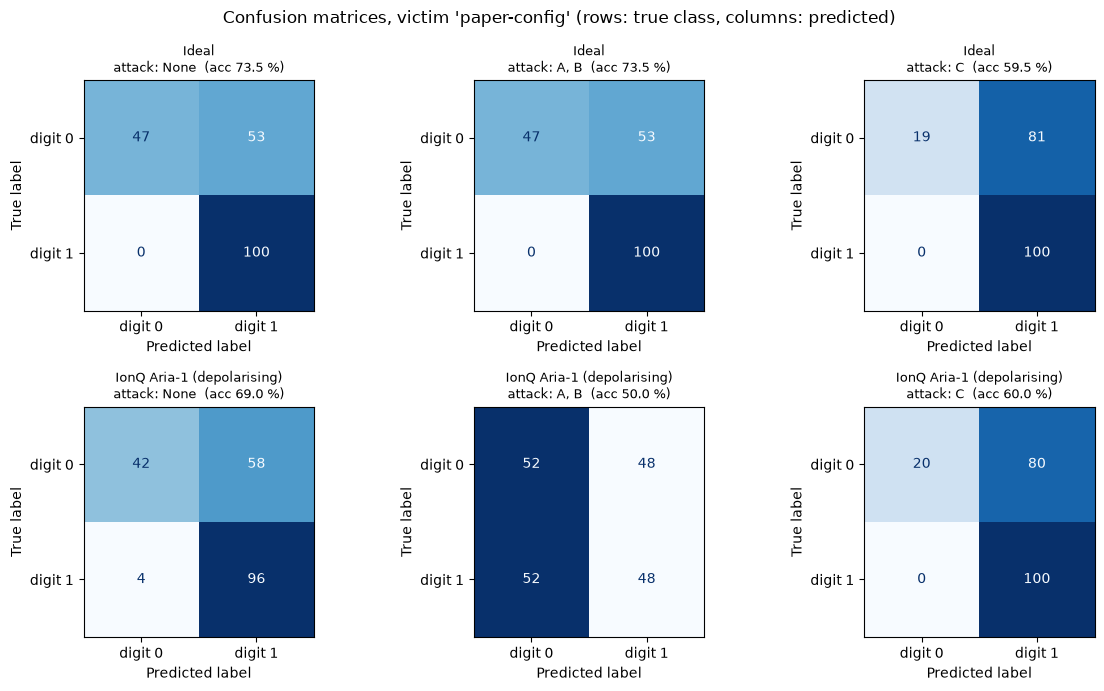

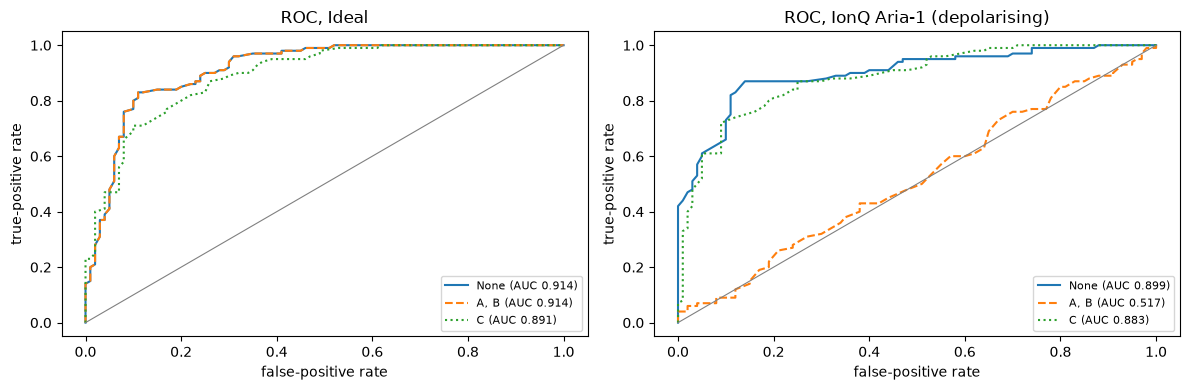

,paper-config,lr1e-2-a,lr1e-2-b,mean,std
Ideal | None,73.5,96.0,93.0,87.50,9.97
"Ideal | A, B",73.5,96.0,93.0,87.50,9.97
Ideal | C,59.5,69.5,72.0,67.00,5.40
IonQ Aria-1 (depolarising) | None,69.0,95.5,93.5,86.00,12.05
"IonQ Aria-1 (depolarising) | A, B",50.0,48.5,48.0,48.83,0.85
IonQ Aria-1 (depolarising) | C,60.0,63.5,65.0,62.83,2.09


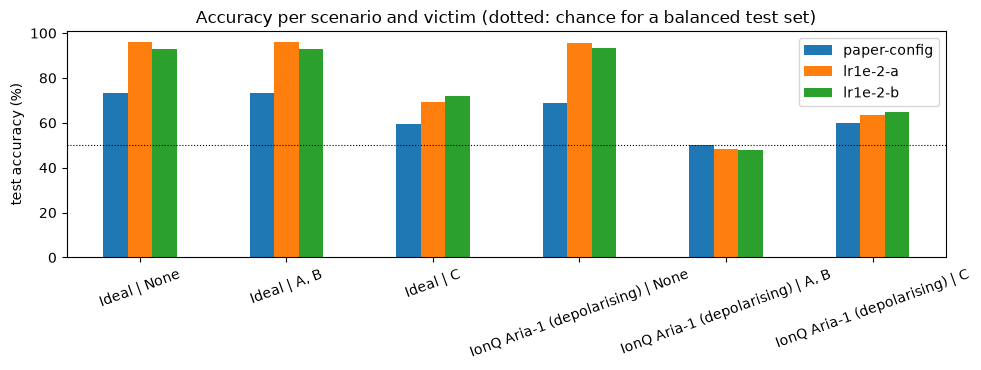

In [19]:
# confusion matrices (attack = digit 1 as positive class) and score distributions for the main victim
main_out = results[0]
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ei, env in enumerate(ENVS):
    for ai, att in enumerate(ATTACKS):
        m = main_out[(env, att)]
        ConfusionMatrixDisplay(m["cm"], display_labels=["digit 0", "digit 1"]).plot(ax=axs[ei, ai], colorbar=False, cmap="Blues")
        axs[ei, ai].set_title(f"{env}\nattack: {att}  (acc {m['acc']:.1f} %)", fontsize=9)
plt.suptitle(f"Confusion matrices, victim '{main['name']}' (rows: true class, columns: predicted)"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ei, env in enumerate(ENVS):
    for att, ls in zip(ATTACKS, ("-", "--", ":")):
        m = main_out[(env, att)]; fpr, tpr, _ = roc_curve(y_test, m["score"])
        axs[ei].plot(fpr, tpr, ls, label=f"{att} (AUC {m['auc']:.3f})")
    axs[ei].plot([0, 1], [0, 1], color="gray", lw=.8); axs[ei].set_title(f"ROC, {env}"); axs[ei].set_xlabel("false-positive rate"); axs[ei].set_ylabel("true-positive rate"); axs[ei].legend(fontsize=8)
plt.tight_layout(); plt.show()

# accuracy of every victim in every scenario
acc_tab = pd.DataFrame({v["name"]: {f"{env} | {att}": out[(env, att)]["acc"] for env in ENVS for att in ATTACKS} for v, out in zip(victims, results)})
acc_tab["mean"] = acc_tab.mean(axis=1); acc_tab["std"] = acc_tab.iloc[:, :-1].std(axis=1, ddof=0)
display(acc_tab.round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
acc_tab.iloc[:, :len(victims)].plot.bar(ax=ax, rot=20); ax.set_ylabel("test accuracy (%)"); ax.axhline(50, color="k", lw=.8, ls=":"); ax.set_title("Accuracy per scenario and victim (dotted: chance for a balanced test set)")
plt.tight_layout(); plt.show()

### How strong must the Class A/B injector be?

The paper uses 50 blocks of depth 3 and observes a moderate drop under IonQ noise (65 % to 57 %). The next cell sweeps the number of
`U^dagger U` blocks in the noisy environment. Blocks are counted back from the VQC (the last *k* blocks), so a sweep point with *k* blocks is
a smaller injector of the same kind. With 0 blocks the model is the benign noisy model.

,paper-config,lr1e-2-a,lr1e-2-b
injector blocks (each = 256 gates),,,
0,69.0,95.5,93.5
1,56.5,77.0,65.0
2,47.5,54.0,45.0
5,52.5,52.0,53.0
10,57.0,49.5,52.0
20,50.0,48.5,48.0
35,50.0,48.5,48.0
50,50.0,48.5,48.0


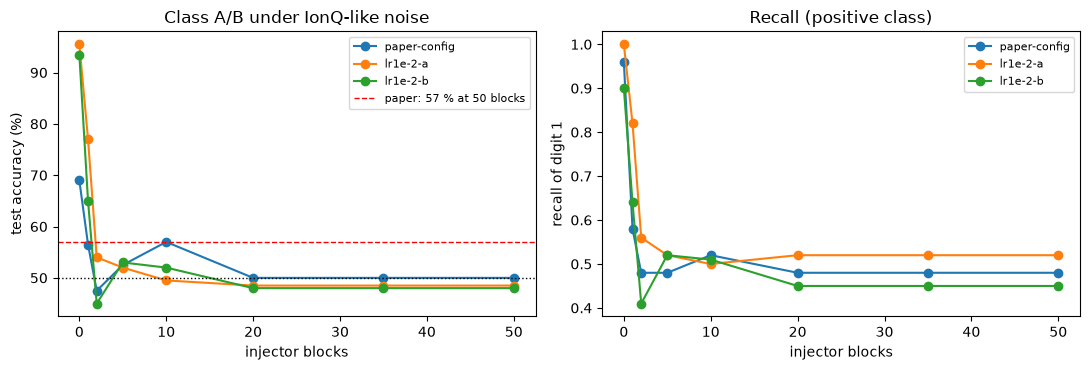

In [20]:
sw_tab = pd.DataFrame({v["name"]: {k: sw[k]["acc"] for k in SWEEP_REPS} for v, sw in zip(victims, sweeps)})
sw_tab.index.name = "injector blocks (each = 256 gates)"
display(sw_tab.round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for v, sw in zip(victims, sweeps):
    ax[0].plot(SWEEP_REPS, [sw[k]["acc"] for k in SWEEP_REPS], "o-", label=v["name"])
    ax[1].plot(SWEEP_REPS, [sw[k]["recall"] for k in SWEEP_REPS], "o-", label=v["name"])
ax[0].axhline(57, color="r", ls="--", lw=1, label="paper: 57 % at 50 blocks"); ax[0].axhline(50, color="k", ls=":", lw=1)
ax[0].set_xlabel("injector blocks"); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_title("Class A/B under IonQ-like noise"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("injector blocks"); ax[1].set_ylabel("recall of digit 1"); ax[1].set_title("Recall (positive class)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### What noise per injected gate would give the paper's moderate drop?

With the stated Aria-1 rates the injector saturates after very few blocks. The cell below keeps the benign network's noise at the paper's rates but scales the noise of
the *injected* gates by a multiplier `m` (`R1Q*m`, `R2Q*m`), for the full injector (`INJ_REPS` blocks), main victim only. The multiplier at which the accuracy
falls from the benign noisy value to about the paper's 57 % shows how much weaker the paper's effective injector noise must have been.

,noise multiplier of the injected gates (0 = benign),accuracy (%),recall
0,0.000,69.0,0.96
1,0.003,65.5,0.95
2,0.010,62.0,0.72
3,0.030,54.5,0.54
4,0.100,51.0,0.49
5,1.000,50.0,0.48


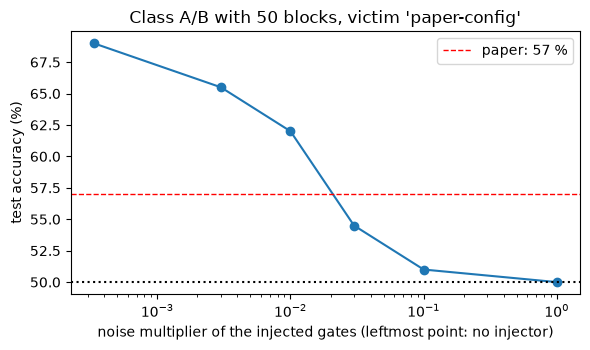

In [21]:
env_i, env_n = list(ENVS)
MULTS = [0.01, 0.1] if FAST_MODE else [0.003, 0.01, 0.03, 0.1]
v0 = victims[0]; r1_, r2_ = ENVS[env_n]
f0 = feats_engine(img_test, v0["params"], r1_, r2_); a0, b0 = vqc_angles(f0); psi0 = product_states(a0, b0)
O_vqc0 = heisenberg(sel_spec(v0["params"][2], N_Q), N_Q, z0_obs(N_Q), r1_, r2_)
inj0 = injector_spec(np.random.default_rng(INJ_SEED), INJ_REPS, INJ_DEPTH)
rows = [[0.0, results[0][(env_n, "None")]["acc"], results[0][(env_n, "None")]["recall"]]]
for m_ in MULTS:
    O_m = heisenberg(inj0, N_Q, O_vqc0, r1_ * m_, r2_ * m_)
    mt = metrics_from(shot_estimate(expectations(psi0, O_m), [SEED, 0, 1]), y_test)
    rows.append([m_, mt["acc"], mt["recall"]])
rows.append([1.0, results[0][(env_n, "A, B")]["acc"], results[0][(env_n, "A, B")]["recall"]])
mult_df = pd.DataFrame(rows, columns=["noise multiplier of the injected gates (0 = benign)", "accuracy (%)", "recall"])
display(mult_df.round(3))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx([max(r[0], 1e-3 / 3) for r in rows], [r[1] for r in rows], "o-"); ax.axhline(57, color="r", ls="--", lw=1, label="paper: 57 %"); ax.axhline(50, color="k", ls=":")
ax.set_xlabel("noise multiplier of the injected gates (leftmost point: no injector)"); ax.set_ylabel("test accuracy (%)")
ax.set_title(f"Class A/B with {INJ_REPS} blocks, victim '{v0['name']}'"); ax.legend(); plt.tight_layout(); plt.show()

### Stealth: size of each Trojan and behaviour in the benign configuration

The paper calls the Trojans "stealthy" because the victim sees nothing in a noise-free test. The table collects what we measured: how many gates each
Trojan adds, whether it changes the ideal output, whether it changes the noisy output, and whether it needs the trigger.

In [22]:
inj_exec = injector_spec(np.random.default_rng(INJ_SEED), INJ_REPS, INJ_DEPTH)
benign_gates = len(sel_spec(wv_demo, N_Q))
env_i, env_n = list(ENVS)
def delta(out, env, att): return out[(env, att)]["acc"] - out[(env, "None")]["acc"]
stealth = pd.DataFrame([
    ["A (noise injector)", len(inj_exec), "no", f"{np.mean([delta(o, env_i, 'A, B') for o in results]):+.1f} pts", f"{np.mean([delta(o, env_n, 'A, B') for o in results]):+.1f} pts", "none (always on)"],
    ["B (ancilla-controlled injector)", len(inj_exec), "ancilla X", f"{np.mean([delta(o, env_i, 'A, B') for o in results]):+.1f} pts", f"{np.mean([delta(o, env_n, 'A, B') for o in results]):+.1f} pts (simulated as A)", "X on ancilla"],
    ["C (Hadamard implant)", N_Q, "ancilla X", f"{np.mean([delta(o, env_i, 'C') for o in results]):+.1f} pts", f"{np.mean([delta(o, env_n, 'C') for o in results]):+.1f} pts", "X on ancilla"],
], columns=["Trojan", "extra gates (executed size)", "dormant until", "accuracy change, ideal", "accuracy change, IonQ-like noise", "trigger"])
print(f"gates of the benign VQC: {benign_gates} (plus the 16-gate encoding); mean over {len(victims)} victims")
display(stealth)

gates of the benign VQC: 64 (plus the 16-gate encoding); mean over 3 victims


,Trojan,extra gates (executed size),dormant until,"accuracy change, ideal","accuracy change, IonQ-like noise",trigger
0,A (noise injector),12800,no,+0.0 pts,-37.2 pts,none (always on)
1,B (ancilla-controlled injector),12800,ancilla X,+0.0 pts,-37.2 pts (simulated as A),X on ancilla
2,C (Hadamard implant),8,ancilla X,-20.5 pts,-23.2 pts,X on ancilla


## 7. Paper versus this notebook

For every number of the paper's Table II (main victim, first row of the victim list) the cell below prints the paper's value, the notebook's value
and a verdict: **reproduced** when within 2 accuracy points (0.02 for precision, recall, F1, AUC and 2 points for impact percentages),
otherwise **not reached** (notebook below the paper) or **exceeded** (above). The "mean over victims" column shows the spread across the trained models.
In `FAST_MODE` the learning rate and the number of epochs differ from the paper, so the benign-model rows are expected to differ.

In [23]:
PAPER = {  # (environment, attack) -> (acc %, precision, recall, F1, AUC)
    (env_i, "None"): (70.00, 1.00, 0.40, 0.5651, 0.9244), (env_i, "A, B"): (70.00, 1.00, 0.40, 0.5651, 0.9244), (env_i, "C"): (50.00, 0.00, 0.00, 0.00, 0.3808),
    (env_n, "None"): (65.00, 1.00, 0.30, 0.4615, 0.9198), (env_n, "A, B"): (57.00, 1.00, 0.14, 0.2456, 0.8998), (env_n, "C"): (50.00, 0.00, 0.00, 0.00, 0.3856)}
KEYS = ["acc", "precision", "recall", "f1", "auc"]; NAMES = ["accuracy (%)", "precision", "recall", "F1", "AUC"]

def verdict(paper, nb, tol):
    if abs(nb - paper) <= tol: return "reproduced"
    return f"exceeded (+{nb - paper:.3g})" if nb > paper else f"not reached ({nb - paper:.3g})"

rows = []
for (env, att), pv in PAPER.items():
    for k, name, p in zip(KEYS, NAMES, pv):
        nb = main_out[(env, att)][k]; mean_nb = np.mean([o[(env, att)][k] for o in results])
        rows.append([f"{env} | {att}", name, p, round(nb, 4), round(mean_nb, 4), verdict(p, nb, 2.0 if k == "acc" else 0.02)])
cmp_df = pd.DataFrame(rows, columns=["scenario", "metric", "paper", "notebook (main victim)", "mean over victims", "verdict"])
pd.set_option("display.max_rows", 100)
display(cmp_df)

# relative impacts quoted in the text of the paper
def impact(out, env, att, k="acc"):
    b = out[(env, "None")][k]; return 100 * (b - out[(env, att)][k]) / b if b > 0 else float("nan")
claims = [
    ("Ideal, A/B: no effect (impact 0 %)",            0.0,   impact(main_out, env_i, "A, B"), 2.0),
    ("Ideal, C: accuracy impact 28.57 %",             28.57, impact(main_out, env_i, "C"), 2.0),
    ("IonQ, A/B: accuracy impact 12.31 %",            12.31, impact(main_out, env_n, "A, B"), 2.0),
    ("IonQ, A/B: recall impact 53.33 %",              53.33, impact(main_out, env_n, "A, B", "recall"), 2.0),
    ("IonQ, C: accuracy impact 23.08 % (abstract: '23 %')", 23.08, impact(main_out, env_n, "C"), 2.0),
    ("IonQ, C: recall and F1 impact 100 %",           100.0, impact(main_out, env_n, "C", "recall"), 2.0),
    ("IonQ, C: AUC impact 58.08 %",                   58.08, impact(main_out, env_n, "C", "auc"), 2.0),
]
claim_df = pd.DataFrame([[c, p, round(n, 2), verdict(p, n, tol)] for c, p, n, tol in claims], columns=["claim (relative impact)", "paper", "notebook", "verdict"])
display(claim_df)

verd = pd.Series(list(cmp_df["verdict"]) + list(claim_df["verdict"]))
print(f"\nsummary over {len(verd)} checked numbers: reproduced {int((verd == 'reproduced').sum())}, "
      f"not reached {int(verd.str.startswith('not reached').sum())}, exceeded {int(verd.str.startswith('exceeded').sum())}")
qual = {
  "Class A/B change nothing on a perfect machine":                  all(abs(delta(o, env_i, 'A, B')) <= 2.0 for o in results),
  "Class C drives a perfect machine to chance level (50 +- 2 %)":   all(abs(o[(env_i, 'C')]['acc'] - 50) <= 2.0 for o in results),
  "Class C drives the noisy machine to chance level (50 +- 2 %)":   all(abs(o[(env_n, 'C')]['acc'] - 50) <= 2.0 for o in results),
  "Class A/B lower the noisy accuracy":                             all(delta(o, env_n, 'A, B') < -2.0 for o in results),
  "Class C removes at least 20 accuracy points (ideal and noisy)":   all(delta(o, env_i, 'C') <= -20 and delta(o, env_n, 'C') <= -20 for o in results),
  "Class C is more damaging than Class A/B under noise":            all(o[(env_n, 'C')]['acc'] < o[(env_n, 'A, B')]['acc'] for o in results),
  "AUC under Class C falls below 0.5 (paper: 0.38)":                all(o[(env_i, 'C')]['auc'] < 0.5 for o in results),
}
for k, ok in qual.items(): print(f"  {'REPRODUCED ' if ok else 'NOT SEEN  '} {k}  (all {len(results)} victims)")

,scenario,metric,paper,notebook (main victim),mean over victims,verdict
0,Ideal | None,accuracy (%),70.0000,73.5000,87.5000,exceeded (+3.5)
1,Ideal | None,precision,1.0000,0.6536,0.8490,not reached (-0.346)
2,Ideal | None,recall,0.4000,1.0000,0.9633,exceeded (+0.6)
3,Ideal | None,F1,0.5651,0.7905,0.8930,exceeded (+0.225)
4,Ideal | None,AUC,0.9244,0.9141,0.9574,reproduced
5,"Ideal | A, B",accuracy (%),70.0000,73.5000,87.5000,exceeded (+3.5)
6,"Ideal | A, B",precision,1.0000,0.6536,0.8490,not reached (-0.346)
7,"Ideal | A, B",recall,0.4000,1.0000,0.9633,exceeded (+0.6)
8,"Ideal | A, B",F1,0.5651,0.7905,0.8930,exceeded (+0.225)
9,"Ideal | A, B",AUC,0.9244,0.9141,0.9574,reproduced


,claim (relative impact),paper,notebook,verdict
0,"Ideal, A/B: no effect (impact 0 %)",0.00,0.00,reproduced
1,"Ideal, C: accuracy impact 28.57 %",28.57,19.05,not reached (-9.52)
2,"IonQ, A/B: accuracy impact 12.31 %",12.31,27.54,exceeded (+15.2)
3,"IonQ, A/B: recall impact 53.33 %",53.33,50.00,not reached (-3.33)
4,"IonQ, C: accuracy impact 23.08 % (abstract: '2...",23.08,13.04,not reached (-10)
5,"IonQ, C: recall and F1 impact 100 %",100.00,-4.17,not reached (-104)
6,"IonQ, C: AUC impact 58.08 %",58.08,1.77,not reached (-56.3)



summary over 37 checked numbers: reproduced 3, not reached 12, exceeded 22
  REPRODUCED  Class A/B change nothing on a perfect machine  (all 3 victims)
  NOT SEEN   Class C drives a perfect machine to chance level (50 +- 2 %)  (all 3 victims)
  NOT SEEN   Class C drives the noisy machine to chance level (50 +- 2 %)  (all 3 victims)
  REPRODUCED  Class A/B lower the noisy accuracy  (all 3 victims)
  NOT SEEN   Class C removes at least 20 accuracy points (ideal and noisy)  (all 3 victims)
  NOT SEEN   Class C is more damaging than Class A/B under noise  (all 3 victims)
  NOT SEEN   AUC under Class C falls below 0.5 (paper: 0.38)  (all 3 victims)


## 8. Reading the paper critically

**What the experiment supports.** Class A and B are, by construction, invisible in a noise-free simulation (asserted above to numerical precision) and become harmful as soon as gate noise is switched on; with the stated per-gate rates they are in fact *more* damaging than the paper reports (accuracy at chance level for every victim). A Hadamard layer between data loading and the trained layers (Class C) does degrade every victim, ideal or noisy, but in the full run only moderately (the section 6 and 7 tables give the per-victim numbers), far from the paper's collapse to 50 %.

**Points the paper leaves open, and what we found.**

1. *The benign model is weak.* The paper's benign accuracy is 70 % with recall 0.40, learning rate 1e-4 and 100 epochs. Our `paper-config` victim shows what that
   training budget gives with the architecture reconstructed from Table I (see the first rows of the comparison). A Trojan "impact" measured against a model that
   already misses most of the positive class is hard to interpret; the better-trained victims give the fairer picture of the damage.
2. *Class C does not collapse the classifier to one answer here.* In the paper the compromised model labels every image "0" (precision, recall and F1 exactly 0, accuracy exactly 50 %, AUC 0.38). In our victims the scrambled output still carries much of the label information: accuracy falls by roughly 13 to 28 percentage points but stays well above chance, recall often stays high, and the AUC stays far above 0.5 (only the FAST_MODE victims, which are small and quickly trained, sometimes dropped to or below chance). What the Hadamard layer does depends on the trained weights, so a constant output is not a general consequence of the implant. A model trained with the paper's tiny learning rate stays close to its random initialisation and is, by the same token, less sensitive to the implant. On a balanced test set any perturbation that destroys the signal gives a table of the kind the paper shows, so the attack should also be compared with controls such as random-rotation implants (Exercise 3).
3. *Class A/B depends entirely on how much noise the injected gates are given.* With the stated Aria-1 rates a block of 256 noisy two-qubit-dominated gates is already enough to wipe out most of the
   signal, and 50 blocks (12,800 gates) leave a state that is numerically the maximally mixed state: `<Z_0>` is then 0 up to sampling error and the classifier is a coin toss. The paper reports a
   *moderate* drop (65 % to 57 %), so its simulator evidently injected much less noise per gate than a per-gate depolarising channel at `r2q = 13.3e-3` (for example, noise on native gates only, or
   the injector compiled away in part). The sweep above shows where the accuracy falls to chance in our model; compare it with the paper's 57 %.
4. *Compilers cancel `U^dagger U`.* Adjacent inverse gates are removed by any optimising transpiler (Qiskit `optimization_level >= 1`, tket, Braket compilers), so a Class-A injector survives only if the attacker
   hides it behind barriers or opaque gates, or if the compiler is not used. The paper discusses the ancilla being optimised away (hence the "Trojan shield") but not this.
5. *"Dormant" is not free on real hardware.* The controlled injector of Class B is a sequence of controlled gates; compiled to native gates it is executed whatever the state of the ancilla, so under
   gate noise a dormant Class-B circuit would already degrade the output. Only in an ideal simulation (checked above) is the dormant circuit identical to the benign one. We therefore simulate the triggered
   Class B as Class A and do not claim to have measured the dormant noisy behaviour.
6. *The trigger and threat model are classical.* Tampering with the compilation configuration file is a supply-chain attack that works against any program; what is quantum here is only the payload.
   The practical defences are equally classical: diff the compiled circuit against the intended one, hash the configuration, and forbid unexplained gates on ancilla qubits.
7. *Statistics.* 200 test images and a single run per setting: one image is half an accuracy point, so the paper's gap between 65 % and 57 % is 16 images. We report several victims and 1024-shot estimates with fixed seeds, but no confidence intervals;
   a bootstrap over the test set is an easy addition (Exercise 4).
8. *Minor reading points.* The three pooling controlled-RZ gates are diagonal and commute with the final Z measurement, so those 3 of the 111 parameters have no effect on the output (checked in section 2). Table II's ideal benign F1 (0.5651) is not what precision 1.00 and recall 0.40 give (2 x 0.4 / 1.4 = 0.571; 0.5651 corresponds to recall 0.394, i.e. 39 of 99 positives), whereas the noisy benign row (recall 0.30, F1 0.4615) is exactly consistent. So the test set is not exactly 100 + 100 images in every row, or a value is mis-rounded; we use 100 + 100.

**Verdict of this notebook.** Class A/B behave as the paper describes (identity when ideal, destructive under noise, even more so with the stated rates; the sweep and the noise-multiplier table show that the paper's moderate 57 % corresponds to far weaker effective noise per injected gate). Class C hurts but does not reproduce the reported collapse. Every number of Table II gets a reproduced, not reached or exceeded verdict in section 7, and the qualitative claims get REPRODUCED or NOT SEEN lines.


## 9. Exercises

1. **Placement.** The paper mounts the Trojan on the last VQC only. Move the Hadamard layer *after* the first `StronglyEntanglingLayers` layer (or to the quanvolution filter) and re-run section 6. Is Class C still as destructive?
2. **Fewer Hadamards.** Replace the 8 Hadamards of Class C by `k = 1 ... 8` of them. How many qubits must the attacker touch before the accuracy drops to chance? Which qubits matter most?
3. **Control experiment.** Replace the Hadamard layer by (a) a layer of random single-qubit rotations and (b) a layer of Pauli-X gates. Is the Hadamard special, or does any state-dependent perturbation do the same? (Use the engine in section 3: add the gate lists with `Rot` and `H` names.)
4. **Uncertainty.** Resample the 200 test images with a bootstrap (1,000 draws) and put 95 % intervals on every accuracy in the Table II layout. Which of the paper's differences (for example 65 % versus 57 %) survive?
5. **Defence.** Add error mitigation to the noisy simulation: scale the two-qubit noise by 1, 2, 3 (`R2Q`) and extrapolate the expectation `<Z_0>` to zero noise (zero-noise extrapolation). Does the Class-A/B damage with 1 to 5 blocks disappear? What happens with 50 blocks? What does this say about the paper's remark that "careful error mitigation" defends against Class A/B?